## Importing necessary libraries

In [237]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os
from matplotlib.ticker import MultipleLocator
from matplotlib.patches import Patch
from scipy.stats import gaussian_kde
import json, glob, shutil, io, base64, inspect, re
import gradio as gr
from PIL import Image

## Importing and exploring data

In [174]:
data_raw = pd.read_csv('data/HSB LIving Lab/HSB_Living_Lab_Water_Consumption_Anonymized.csv',sep=';')
#data_raw.head()
data_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 652315 entries, 0 to 652314
Data columns (total 16 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   timestamp         652315 non-null  object 
 1   date              652315 non-null  object 
 2   hour              652315 non-null  int64  
 3   day_of_week       652315 non-null  int64  
 4   day_name          652315 non-null  object 
 5   month             652315 non-null  int64  
 6   year              652315 non-null  int64  
 7   sensor_id         652315 non-null  object 
 8   apartment         498046 non-null  object 
 9   cluster_name      610517 non-null  object 
 10  room_number       652315 non-null  object 
 11  room_type         652315 non-null  object 
 12  type              652315 non-null  object 
 13  attached_to       652315 non-null  object 
 14  value             652315 non-null  float64
 15  aggregated_value  652315 non-null  float64
dtypes: float64(2), int64

In [175]:
# change timestamp and date to relevant data types
data_raw['timestamp'] = pd.to_datetime(data_raw['timestamp'])
data_raw['date'] = pd.to_datetime(data_raw['date'])

In [176]:
# drop some columns we do not need
data_raw = data_raw.drop(columns=['day_name', 'month', 'year', 'cluster_name','aggregated_value'])
data_raw.head()

,timestamp,date,hour,day_of_week,sensor_id,apartment,room_number,room_type,type,attached_to,value
0,2019-12-31,2019-12-31,0,1,S0101,APT_005,R025,Bathroom,cold water consumption,Toilet,0.010
1,2019-12-31,2019-12-31,0,1,S0161,APT_020,R046,Living room,hot water consumption,Kitchen tap,0.006
2,2019-12-31,2019-12-31,0,1,S0162,APT_020,R046,Living room,cold water consumption,Kitchen tap,0.003
3,2019-12-31,2019-12-31,0,1,S0012,APT_009,R008,Living room,hot water consumption,Washbasin,0.004
4,2019-12-31,2019-12-31,0,1,S0163,APT_020,R046,Living room,hot water consumption,Washbasin,0.001


In [177]:
# list the appliances that are metered separately
print(*data_raw['attached_to'].unique(), sep='\n')

Toilet
Kitchen tap
Washbasin
Shower
Washing machine


In [178]:
# which room types do we have
rooms = (data_raw['room_type'].unique())
print(*rooms, sep='\n') 

Bathroom
Living room
Shared bathroom
Kitchen
Shared space
Laundry studio
Cleaning


In [179]:
# let us see how many apartments values are missing
complete = data_raw.shape[0]
missing = data_raw['apartment'].isna().sum()
print(f'The missing apartment data is {missing/complete:.2%}')   #or print(f'The missing data is {(missing/complete) * 100:.2f}%')
print(f'We would be left with {complete-missing} rows to work with if we deleted the rows')

The missing apartment data is 23.65%
We would be left with 498046 rows to work with if we deleted the rows


In [180]:
# other than NaN values, are there really 28 apartments?
data_raw['apartment'].nunique()                         # yes 28

28

#### how do we deal with the missing apartment values

In [181]:
apartments = (data_raw['apartment'].unique())
missing_apt = data_raw[data_raw['apartment'].isna()]
not_missing_apt = data_raw[data_raw['apartment'].notna()]

In [182]:
list(missing_apt['room_type'].unique()) == list(not_missing_apt['room_type'].unique())

False

In [183]:
missing_apt[missing_apt['attached_to']=='Shower'].shape[0]

34318

In [184]:
not_missing_apt.groupby(
    ['room_type', 'attached_to']
).agg(
    records=('value', 'size'),
    total_litres=('value', 'sum'),
    sensors=('sensor_id', 'nunique'),
    rooms=('room_number', 'nunique')
 ).sort_values('total_litres', ascending=False)

records  total_litres  sensors  rooms
room_type    attached_to                                           
Bathroom     Toilet             58418       355.648        5      5
Living room  Toilet             78741       332.395       21     20
Bathroom     Shower             24733       305.848       10      5
Living room  Kitchen tap        85033       272.435       47     23
Shared space Kitchen tap        78784       258.126        6      3
Living room  Washbasin          98619       202.512       46     22
Bathroom     Washbasin          52765       104.504       10      5
             Washing machine     7698        91.163        3      3
Kitchen      Kitchen tap        13255        63.833        4      2

In [185]:
missing_apt.groupby(
    ['room_type', 'attached_to']
).agg(
    records=('value', 'size'),
    total_litres=('value', 'sum'),
    sensors=('sensor_id', 'nunique'),
    rooms=('room_number', 'nunique')
 ).sort_values('total_litres', ascending=False)

,,records,total_litres,sensors,rooms
room_type,attached_to,,,,
Shared bathroom,Shower,34318,642.202,14,8
Shared space,Kitchen tap,57236,212.189,8,4
Laundry studio,Washing machine,19046,160.024,8,1
Bathroom,Toilet,8093,114.086,2,2
Shared bathroom,Toilet,10525,51.975,8,7
Bathroom,Washbasin,8323,46.812,4,2
Laundry studio,Washbasin,3859,26.154,2,1
Shared bathroom,Washbasin,10392,23.434,15,8
Cleaning,Washbasin,2477,7.449,1,1


#### Observation
- the missing values do not share common sensors with rows with filled in apartment numbers
- the missing alues also have no matching room numbers with the filled in ones
- while some have a cluster that does not break down the apartment number (however some entries have no cluster entries in addition to missing apartment values)
- the only room types missing in this data are living_room an kitchen while those with apartment would lack laundry room, cleaning and shared bathroom


- while the missing apartment data could be removed, it carries too much data on the events with high water consumption
- it therefore rather makes more sense to do an analysis by event rather than apartment

#### Kaggle Data

In [186]:
data_2 = pd.read_csv('data/kaggle/household_water_consumption.csv')
data_2.head()

,Date,Household_ID,Bathroom_Liters,Kitchen_Liters,Laundry_Liters,Gardening_Liters,Total_Liters
0,2025-01-01,7,248,162,110,100,620
1,2025-01-02,20,321,111,241,7,680
2,2025-01-03,15,253,101,67,52,473
3,2025-01-04,11,363,61,86,59,569
4,2025-01-05,8,368,88,86,107,649


In [187]:
cols = ['Bathroom_Liters', 'Kitchen_Liters', 'Laundry_Liters', 'Gardening_Liters']

sums = data_2[cols].sum().sort_values(ascending=False)
share = (sums / sums.sum() * 100).round(1)

summary = pd.DataFrame({'Liters': sums, 'Share_%': share})
summary


,Liters,Share_%
Bathroom_Liters,28595,43.9
Laundry_Liters,14924,22.9
Kitchen_Liters,14153,21.7
Gardening_Liters,7466,11.5


In [188]:
act_cols = ['Bathroom_Liters', 'Kitchen_Liters', 'Laundry_Liters', 'Gardening_Liters']

by_house = (
    data_2
    .groupby('Household_ID')[act_cols + ['Total_Liters']]
    .sum()
    .sort_values('Total_Liters', ascending=False)
)

shares = by_house[act_cols].div(by_house['Total_Liters'], axis=0).mul(100).round(1)
shares.columns = [c.replace('_Liters', '_%') for c in act_cols]

shares.head()

,Bathroom_%,Kitchen_%,Laundry_%,Gardening_%
Household_ID,,,,
8,46.8,20.7,21.4,11.1
7,40.8,26.7,22.8,9.6
15,45.7,24.1,18.5,11.7
12,37.1,22.3,24.9,15.6
4,42.7,16.7,27.8,12.8


#### Observation
- The Kaggle data confirms the same observation that showers/ bathrooms ccount for the highest water consumption
- we will proceed with only the HSB Living data anyway since it has better time resolution

##### Clusters

In [189]:
# I felt that clusters carry no significant information so no need to keep them 

# pd.crosstab(
#    data_raw['room_number'],
#    data_raw['cluster_name']
#)

In [190]:
#pd.crosstab(
#    data_raw['cluster_name'],
#    data_raw['attached_to']
#)

##### Sensors

In [191]:
#sensor_mapping = (
#   data_raw
#    .groupby('sensor_id')
#    .agg(
#        apartments=('apartment', 'nunique'),
#        apartment_values=('apartment', lambda x: x.dropna().unique().tolist()),
#        rooms=('room_number', 'nunique'),
#        room_types=('room_type', 'nunique'),
#        fixtures=('attached_to', 'nunique')
#    )
#)

#sensor_mapping.sample(15)

### Exploring water consumption events

In [192]:
#it is first crucial to establish if the appliances are only assciated with one room type or not
pd.crosstab(data_raw['attached_to'], data_raw['room_type'])

room_type,Bathroom,Cleaning,Kitchen,Laundry studio,Living room,Shared bathroom,Shared space
attached_to,,,,,,,
Kitchen tap,0,0,13255,0,85033,0,136020
Shower,24733,0,0,0,0,34318,0
Toilet,66511,0,0,0,78741,10525,0
Washbasin,61088,2477,0,3859,98619,10392,0
Washing machine,7698,0,0,19046,0,0,0


#### Observation
- it could be one appliance by name but reflects usage in different rooms, summing up consumption by appliance might not reflect the same behaviour (e.g. toilet in the living room might also be guests)

In [193]:
# we sort the activities according to water consumption share
highest_activity = (data_raw.groupby(['attached_to', 'type'])['value'].sum().unstack('type'))
highest_activity.columns = ['cold', 'hot']   
highest_activity['total'] = highest_activity.sum(axis=1)        #sum of all the water consumption
highest_activity = highest_activity.sort_values('total', ascending=False)
highest_activity['share_of_total_%'] = (highest_activity['total'] / highest_activity['total'].sum() * 100).round(2)
highest_activity

,cold,hot,total,share_of_total_%
attached_to,,,,
Shower,337.581,610.469,948.050,28.99
Toilet,854.104,NaN,854.104,26.11
Kitchen tap,410.704,395.879,806.583,24.66
Washbasin,240.296,170.569,410.865,12.56
Washing machine,230.511,20.676,251.187,7.68


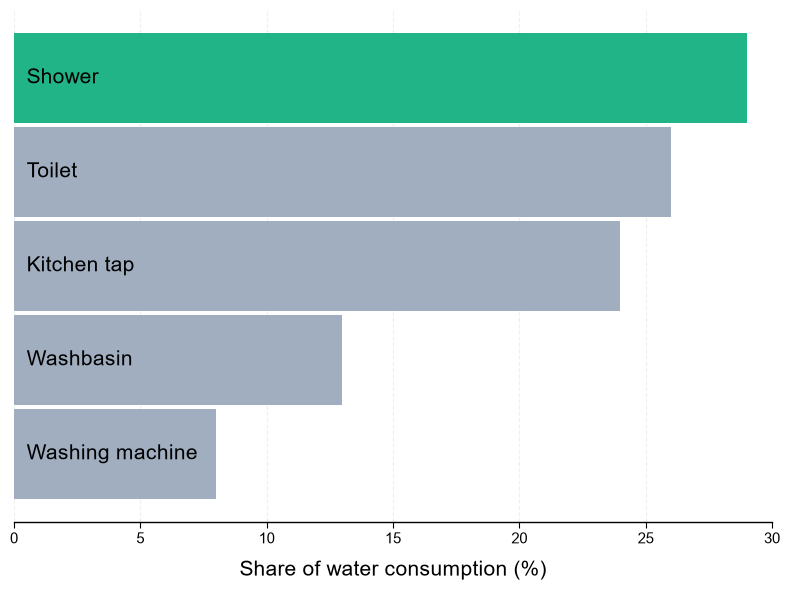

In [194]:
# Plotting for presentation

# Set Arial font family globally
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Arial"]

# Data
activities = [
    "Shower",
    "Toilet",
    "Kitchen tap",
    "Washbasin",
    "Washing machine"
]

ratings = [29, 26, 24, 13, 8]

# Shower green, rest muted grey
colors = [
    "#20B486",# Green
    "#A0AEC0",  # Muted grey
    "#A0AEC0",
    "#A0AEC0",
    "#A0AEC0"
]

fig, ax = plt.subplots(figsize=(8, 6))

y = np.arange(len(activities))

# set bars
bars = ax.barh(
    y,
    ratings,
    height=0.95,
    color=colors,
    edgecolor="none"
)

# Highest value at top and remove y-axis labels
ax.invert_yaxis()
ax.set_yticks([])

# Regular weight, black text labels inside the bars
for bar, name in zip(bars, activities):
    y_center = bar.get_y() + bar.get_height() / 2
    ax.text(
        0.5, y_center, name,
        va="center", ha="left", color="#000000", fontweight="normal",
        fontsize=15
    )

# Cap at 30%
ax.set_xlim(0, 30)

# Keep bottom spine (X-axis line) visible
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_visible(True)
ax.spines["bottom"].set_color("#000000")
ax.spines["bottom"].set_linewidth(1.0)

# X-axis tick settings
ax.tick_params(
    axis="x",
    colors="#000000",
    labelsize=11,
    length=4,
    direction="out"
)

# Subtle vertical grid lines
ax.xaxis.grid(
    True,
    linestyle="--",
    linewidth=0.85,
    alpha=0.18
)
ax.set_axisbelow(True)

# X-axis title
ax.set_xlabel(
    "Share of water consumption (%)",
    fontsize=15,
    color="#000000",
    labelpad=10
)

plt.tight_layout()
plt.savefig("water_consumption_chart.png", dpi=300, bbox_inches="tight")
plt.show()

### Further analysis on showering events

In [195]:
showers = data_raw[data_raw['attached_to'] == 'Shower'].copy()

# checking showers per room (bathroom or shared bathroom)
showers.groupby('room_number').agg(
    room_type=('room_type', 'first'),
    apartment=('apartment', 'first'),
    sensors=('sensor_id', 'nunique'),
    water_types=('type', 'nunique')
)

,room_type,apartment,sensors,water_types
room_number,,,,
R011,Shared bathroom,None,1,1
R012,Shared bathroom,None,1,1
R020,Shared bathroom,None,2,2
R021,Shared bathroom,None,2,2
R022,Bathroom,APT_002,2,2
R025,Bathroom,APT_005,2,2
R026,Bathroom,APT_006,2,2
R028,Bathroom,APT_003,2,2
R030,Bathroom,APT_017,2,2


##### Observation
- the most rooms have hot and cold water supply with a sensor per type
- R011 and R012 are the only rooms with just cold water (could make sense to look at what influence this may have)

In [196]:
# keeping hot and old water separated 
hot_rooms = showers[showers['type'] == 'hot water consumption']['room_number'].unique()       # excludes R011 and R012

# unit of value: the data dictionary says litres, but the magnitudes only make sense as m3 (**assumption**)
unit_to_litres = 1000   
showers['litres'] = showers['value'] * unit_to_litres

#showers.sample(10)

#### Building the shower events
- an event will be terminated once there is no reading for 10 minutes (a typical shower is between 8 an 15 minutes)
- hot and cold are put side by side per room and timestamp first

In [197]:
shower_ts = (
    showers
    .pivot_table(index=['room_number', 'timestamp'], columns='type', values='litres', aggfunc='sum', fill_value=0)
    .reset_index()
)
shower_ts.columns = ['room_number', 'timestamp', 'cold', 'hot']
shower_ts = shower_ts.sort_values(['room_number', 'timestamp'])
# shower_ts.head()

In [198]:
# sort so each room's events are in time order 
shower_ts = shower_ts.sort_values(['room_number', 'timestamp']).reset_index(drop=True)

# time since the previous event in the same room, in seconds (the diff must not be more than 10 minutes between water readings)
gap = shower_ts.groupby('room_number')['timestamp'].diff().dt.total_seconds()

# new event when it's the first row of a room (NaN) or the gap is > 10 min
new_event = gap.isna() | (gap > 600)
shower_ts['event_id'] = new_event.astype(int).cumsum()

#shower_ts.tail(15)

In [199]:
# we will use the event ids to create a summary for each shower event
events = (
    shower_ts
    .groupby('event_id')
    .agg(
        room_number=('room_number', 'first'),           # the room number, basically just one of the bathrooms/shared bathrooms (first value of the group)
        start=('timestamp', 'min'),                     # when the shower starts
        intervals=('timestamp', 'size'),                # this records the frequency of water flow after there had been a pause but still within a 10 minute window
        cold_l=('cold', 'sum'),                         # sum of consumed cold water
        hot_l=('hot', 'sum')                            # sum of consumed hot water
    )
)
# add new columns
events['total_l'] = events['cold_l'] + events['hot_l']
events['hot_metered'] = events['room_number'].isin(hot_rooms)
events['hot_share_%'] = (events['hot_l'] / events['total_l'] * 100)#.where(events['hot_metered'])
events['duration_min'] = events['intervals'] * 10       # a rough duration of the shower
events['start_hour'] = events['start'].dt.hour      
events['period'] = pd.cut(                              # creating time labels from start_hour
    events['start_hour'],
    bins=[-1, 5, 11, 17, 23],
    labels=['night', 'morning', 'afternoon', 'evening'] # night (0 to 5), morning (6 to 11), afternoon (12 to 17), evening (18 to 23)
)

# events with a hot sensor: use for litres, hot share and the scenario (R011/R012 would understate the volume)
events_hot = events[events['hot_metered']].copy()
events.head()

,room_number,start,intervals,cold_l,hot_l,total_l,hot_metered,hot_share_%,duration_min,start_hour,period
event_id,,,,,,,,,,,
1,R011,2019-12-31 11:50:00,2,13.0,0.0,13.0,False,0.0,20,11,morning
2,R011,2019-12-31 13:50:00,2,28.0,0.0,28.0,False,0.0,20,13,afternoon
3,R011,2020-01-02 07:40:00,3,35.0,0.0,35.0,False,0.0,30,7,morning
4,R011,2020-01-02 14:30:00,1,8.0,0.0,8.0,False,0.0,10,14,afternoon
5,R011,2020-01-03 13:50:00,2,7.0,0.0,7.0,False,0.0,20,13,afternoon


saved: figures\shower_length_chart.png


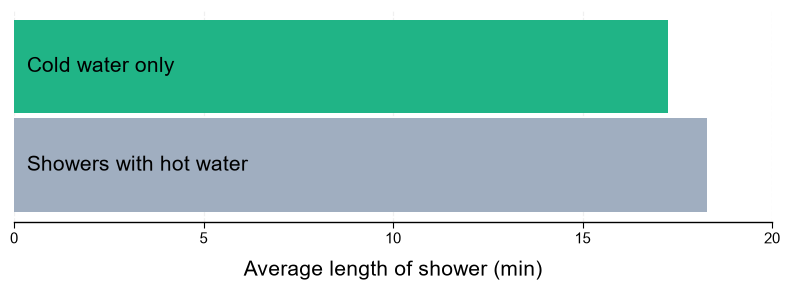

saved: figures\shower_water_chart.png


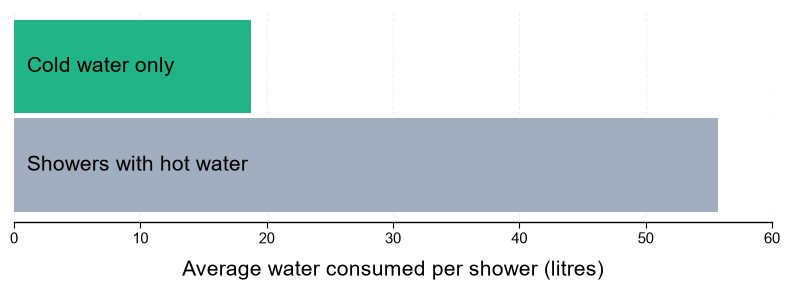

In [200]:
# comparison between cold and hot showers

# Plotting for presentation
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Arial"]

d = events.copy()                       # all showers
d['group'] = np.where(d['hot_metered'], 'Showers with hot water', 'Cold water only')
order = ['Cold water only', 'Showers with hot water']
avg = d.groupby('group').agg(minutes=('duration_min', 'mean'), litres=('total_l', 'mean')).loc[order]

colors = ["#20B486", "#A0AEC0"]   # cold-only green, rest muted grey

save = True                         
save_dir = "figures"                

def slide_bar(values, xlabel, xmax, step, filename):
    # every call draws its own, independent figure (one chart per image)
    fig = plt.figure(figsize=(8, 3))
    ax = fig.add_subplot(1, 1, 1)
    y = np.arange(len(values))
    bars = ax.barh(y, values.values, height=0.95, color=colors, edgecolor="none")

    ax.invert_yaxis()
    ax.set_yticks([])

    # black text labels inside the bars
    for bar, name in zip(bars, values.index):
        y_center = bar.get_y() + bar.get_height() / 2
        ax.text(xmax * 0.017, y_center, name, va="center", ha="left", color="#000000", fontweight="normal", fontsize=15)

    ax.set_xlim(0, xmax)
    ax.xaxis.set_major_locator(MultipleLocator(step))      # whole numbers only

    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_visible(True)
    ax.spines["bottom"].set_color("#000000")
    ax.spines["bottom"].set_linewidth(1.0)

    ax.tick_params(axis="x", colors="#000000", labelsize=11, length=4, direction="out")
    ax.xaxis.grid(True, linestyle="--", linewidth=0.85, alpha=0.18)
    ax.set_axisbelow(True)
    ax.set_xlabel(xlabel, fontsize=15, color="#000000", labelpad=10)

    fig.tight_layout()
    if save:
        os.makedirs(save_dir, exist_ok=True)
        path = os.path.join(save_dir, filename)
        fig.savefig(path, dpi=300, bbox_inches="tight")
        print(f"saved: {path}")
    plt.show()
    plt.close(fig)

# 1. average shower time (whole-number ticks up to 20)
slide_bar(avg['minutes'], "Average length of shower (min)", xmax=20, step=5, filename="shower_length_chart.png")

# 2. average water per shower
slide_bar(avg['litres'], "Average water consumed per shower (litres)", xmax=60, step=10, filename="shower_water_chart.png")

In [201]:
# using time of the day to get a summary of showers
period_summary = (
    events
    .groupby('period', observed=True)
    .agg(
        showers=('total_l', 'size'),
        avg_duration_min=('duration_min', 'mean')
    )
    .round(1)
)
period_summary['share_of_showers_%'] = (period_summary['showers'] / period_summary['showers'].sum() * 100).round(1)

period_volume = (
    events_hot
    .groupby('period', observed=True)
    .agg(
        avg_cold_l=('cold_l', 'mean'),
        avg_hot_l=('hot_l', 'mean'),
        avg_total_l=('total_l', 'mean'),
        median_total_l=('total_l', 'median')
    )
    .round(1)
)
period_volume['hot_share_%'] = (period_volume['avg_hot_l'] / period_volume['avg_total_l'] * 100).round(1)

period_summary = period_summary.join(period_volume)
period_summary

,showers,avg_duration_min,share_of_showers_%,avg_cold_l,avg_hot_l,avg_total_l,median_total_l,hot_share_%
period,,,,,,,,
night,631,17.5,3.4,18.1,36.9,55.0,33.0,67.1
morning,6554,17.2,35.6,15.6,30.6,46.2,32.0,66.2
afternoon,5182,18.9,28.1,20.7,42.0,62.7,42.0,67.0
evening,6065,18.7,32.9,19.3,41.5,60.8,43.0,68.3


saved: figures\showers_by_period_butterfly.png


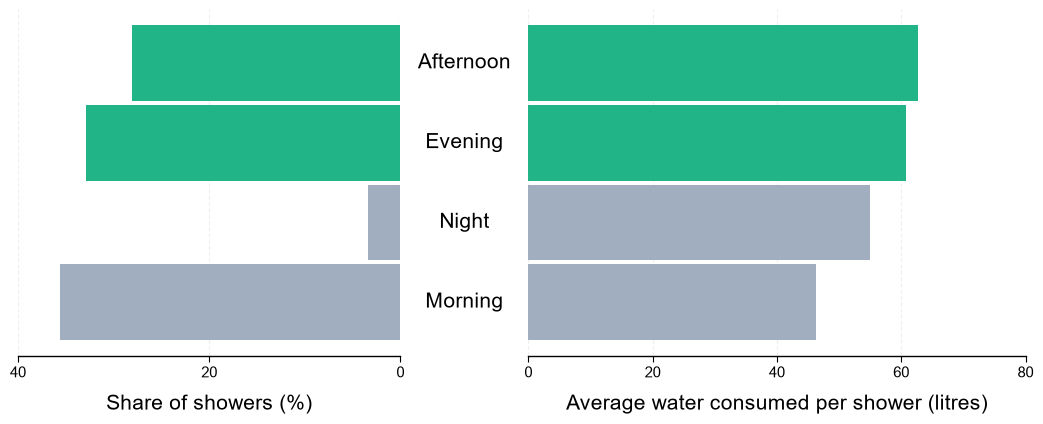

In [202]:
# Plotting for presentation
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Arial"]

# Data
share = events['period'].astype(str).value_counts(normalize=True) * 100                                             # all showers
litres = events_hot.assign(period=events_hot['period'].astype(str)).groupby('period')['total_l'].mean()             # rooms with a hot sensor

order = litres.sort_values(ascending=False).index.tolist()     # most water per shower at the top
share, litres = share.reindex(order), litres.reindex(order)
colors = ["#20B486" if p in ('afternoon', 'evening') else "#A0AEC0" for p in order]    # afternoon and evening green, the rest muted grey

save = True
save_dir = "figures"

fig = plt.figure(figsize=(13, 4.5))
gs = fig.add_gridspec(1, 3, width_ratios=[5, 1.5, 6.5], wspace=0.02)
ax_l = fig.add_subplot(gs[0])
ax_m = fig.add_subplot(gs[1], sharey=ax_l)      # middle column for the period names
ax_r = fig.add_subplot(gs[2], sharey=ax_l)
y = np.arange(len(order))

# left: share of showers (bars grow to the left)
ax_l.barh(y, share.values, height=0.95, color=colors, edgecolor="none")
ax_l.set_xlim(40, 0)
ax_l.xaxis.set_major_locator(MultipleLocator(20))
ax_l.set_xlabel("Share of showers (%)", fontsize=15, labelpad=10)

# middle: period names
ax_m.set_xlim(0, 1)
for yi, p in zip(y, order):
    ax_m.text(0.5, yi, p.capitalize(), va="center", ha="center", color="#000000", fontsize=15)
ax_m.axis("off")

# right: average water per shower
ax_r.barh(y, litres.values, height=0.95, color=colors, edgecolor="none")
ax_r.set_xlim(0, 80)
ax_r.xaxis.set_major_locator(MultipleLocator(20))
ax_r.set_xlabel("Average water consumed per shower (litres)", fontsize=15, labelpad=10)

ax_l.invert_yaxis()                      # shared y axis: inverts all three
ax_l.set_yticks([])

for ax in (ax_l, ax_r):
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color("#000000")
    ax.spines["bottom"].set_linewidth(1.0)
    ax.tick_params(axis="x", colors="#000000", labelsize=11, length=4, direction="out")
    ax.xaxis.grid(True, linestyle="--", linewidth=0.85, alpha=0.18)
    ax.set_axisbelow(True)

if save:
    os.makedirs(save_dir, exist_ok=True)
    path = os.path.join(save_dir, "showers_by_period_butterfly.png")
    fig.savefig(path, dpi=300, bbox_inches="tight")
    print(f"saved: {path}")
plt.show()
plt.close(fig)
#pd.DataFrame({'share_of_showers_%': share, 'avg_litres_per_shower': litres}).round(1)

##### Observation
- the hot share is almost the same in every period (66.3-68.3%), so one hot/cold mix is enough for the scenario, nothing time-dependent is needed for the hot water cap
- mornings are 37.3% of the showers but only 31.0% of the litres: the average morning shower is 46.2 L against 62.7 L in the afternoon and 60.8 L in the evening
        - people take quick showers in the morning 
- afternoon and evening showers are a bit longer (1.9 and 1.9 intervals against 1.7) and more intense (32.9 and 32.1 against 26.8 L per interval)
        - people take relaxed showers in these time periods
- night is only 3.4% of the showers, too few to draw conclusions: it stays in the tables but gets no own scenario
        - perhaps this time cluster does not fit a lot of people's schedules to inform enough
- the time of day tells where the most savings will sit 

In [203]:
#strictly looking at hot water showers
#period_view = (
#    events_hot
#    .groupby('period', observed=True)
#    .agg(
#        showers=('total_l', 'size'),
#        litres=('total_l', 'sum'),
#        hot_litres=('hot_l', 'sum'),
#        intervals=('intervals', 'sum'),
#        avg_total_l=('total_l', 'mean'),
#        avg_intervals=('intervals', 'mean')
#    )
#)
#period_view['share_of_showers_%'] = period_view['showers'] / period_view['showers'].sum() * 100
#period_view['share_of_litres_%'] = period_view['litres'] / period_view['litres'].sum() * 100
#period_view['l_per_interval'] = period_view['litres'] / period_view['intervals']
#period_view['hot_share_%'] = period_view['hot_litres'] / period_view['litres'] * 100

#period_view[['showers', 'share_of_showers_%', 'share_of_litres_%', 'avg_total_l', 'avg_intervals', 'l_per_interval', 'hot_share_%']].round(1)

In [204]:
# looking at the showers by the hour
hourly = events.groupby('start_hour').agg(showers=('total_l', 'size'))

hourly_volume = (
    events_hot
    .groupby('start_hour')
    .agg(
        avg_total_l=('total_l', 'mean'),
        avg_hot_l=('hot_l', 'mean'),
        avg_cold_l=('cold_l', 'mean')
    )
    .round(1)
)

hourly = hourly.join(hourly_volume).sort_values('showers', ascending=False)
hourly.head(3)

,showers,avg_total_l,avg_hot_l,avg_cold_l
start_hour,,,,
7,1644,37.3,24.4,12.9
8,1251,47.7,31.9,15.7
20,1223,54.6,37.5,17.0


##### Observation
- while most showers are in the morning,the water consumed is lesser
- night showers are less common but they too seem to be intense

In [205]:
# looking at showers by room
room_summary = (
    events
    .groupby('room_number')
    .agg(
        showers=('total_l', 'size'),
        hot_metered=('hot_metered', 'first'),
        avg_duration_min=('duration_min', 'mean'),
        p25_total_l=('total_l', lambda x: x.quantile(0.25)),
        median_total_l=('total_l', 'median'),
        avg_total_l=('total_l', 'mean'),
        hot_share_pct=('hot_share_%', 'mean')
    )
    .round(1)
)
room_info = showers.groupby('room_number').agg(room_type=('room_type', 'first'), apartment=('apartment', 'first'))
room_summary = room_info.join(room_summary).sort_values('median_total_l')
#room_summary

#### R011 and R012: are the showers colder or smaller?
- there is no hot sensor, so only the cold side can be compared
- if they really showered cold, the cold litres would be a whole shower (around 55 L)
- if the hot water is just not metered, the cold litres should look like the cold part of the other rooms

In [206]:
# comparing cold and hot showers
cold_check = (
    events
    .groupby('hot_metered')
    .agg(
        showers=('cold_l', 'size'),
        avg_duration_min=('duration_min', 'mean'),
        avg_cold_l=('cold_l', 'mean'),
        median_cold_l=('cold_l', 'median')
    )
    .round(1)
)
cold_check.index = ['R011/R012 (no hot sensor)', 'rooms with hot sensor']
cold_check

,showers,avg_duration_min,avg_cold_l,median_cold_l
R011/R012 (no hot sensor),2127,17.3,18.8,14.0
rooms with hot sensor,16305,18.3,18.3,13.0


In [207]:
# how often showers in the rooms with a hot sensor are really cold only, and how big they are
cold_showers = events_hot[events_hot['hot_l'] == 0]
print(f'Showers without hot water in the other rooms: {len(cold_showers)/len(events_hot):.1%}')

Showers without hot water in the other rooms: 1.5%


#### Observation
- the cold litres per shower in R011/R012 are almost the same as the cold part in the other rooms, in every period
- only 1.5% of the showers elsewhere are cold only
- this could also point to the hot water not being metered, not to colder or smaller showers

In [208]:
# private vs shared
private_rooms = showers[showers['apartment'].notna()]['room_number'].unique()
events_hot['bathroom'] = np.where(events_hot['room_number'].isin(private_rooms), 'private', 'shared')

bathroom_view = (
    events_hot
    .groupby('bathroom')
    .agg(
        rooms=('room_number', 'nunique'),
        showers=('total_l', 'size'),
        avg_total_l=('total_l', 'mean'),
        median_total_l=('total_l', 'median'),
        avg_intervals=('intervals', 'mean'),
        long_showers_pct=('intervals', lambda x: (x >= 4).mean() * 100)
    )
    .round(1)
)
bathroom_view

,rooms,showers,avg_total_l,median_total_l,avg_intervals,long_showers_pct
bathroom,,,,,,
private,5,7444,41.1,27.0,1.8,5.2
shared,6,8861,68.0,53.0,1.9,5.1


##### Observation
- shared bathrooms have the larger showers (68.0 L on average against 41.1 L in private ones), while the share of long showers (4 or more intervals) is the same (5.1% and 5.2%): merged back-to-back showers do not explain the difference
- the three rooms with the lowest volumes (R030, R026, R025) are all private bathrooms, so the internal benchmark for an efficient shower comes from private bathrooms and the shared ones would have to change much more

# To AquaSave
This section builds the scenario definition step by step. Every parameter is tied to
1. an observation from the shower events, and
2. a source from the literature.

It continues from the shower analysis (`events`, `events_hot`, `shower_ts`, `showers`, `hot_rooms`)

- litres are `value * unit_to_litres` (1000)
- only rooms with a hot sensor are used for volumes (R011 and R012 stay in the counts but not in the litres)

## 1. The baseline from the shower events

In [209]:
# from the previous analysis, we look at the showering pattern
baseline = pd.Series({
    'showers (rooms with hot sensor)': len(events_hot),
    'total water (m3)': events_hot['total_l'].sum() / 1000,
    'hot water (m3)': events_hot['hot_l'].sum() / 1000,
    'average shower (L)': events_hot['total_l'].mean(),
    'median shower (L)': events_hot['total_l'].median(),
    'litres in the largest 10% of showers (%)': events_hot.nlargest(int(len(events_hot) * 0.1), 'total_l')['total_l'].sum() / events_hot['total_l'].sum() * 100,
    'hot share (%)': events_hot['hot_l'].sum() / events_hot['total_l'].sum() * 100
}).round(1)
baseline

showers (rooms with hot sensor)             16305.0
total water (m3)                              908.1
hot water (m3)                                610.5
average shower (L)                             55.7
median shower (L)                              37.0
litres in the largest 10% of showers (%)       34.0
hot share (%)                                  67.2
dtype: float64

##### Observation
- the average shower (55.7 L) is well above the median (37.0 L): a few large showers carry a lot of the water, the largest 10% hold 34.0% of all the water consumed
- this indicates that the the total cap on water consumption can be applied to these showers
- literature states a 40-150 L range per shower, whereas our analysed showers sit at the lower end of that range already 

## 2. Setting the scenario parameters
Each parameter gets a value from the literature, a check against our own data, and a confidence.

### 2.1 flow_reduction: efficient shower head

In [210]:
# literature inputs (sources at the end of the notebook)
eff_flow_lpm = 7.5   # water saving shower heads: below 9 L/min, good ones 6-8 L/min, middle of the range
shower_min = 6       # target of a short shower, typical durations in the sources are 6-11 min

# rough flow rate: litres per minute in the middle intervals of showers with 3 or more intervals
hot_ts = shower_ts[shower_ts['room_number'].isin(hot_rooms)].copy()
hot_ts['n'] = hot_ts.groupby('event_id')['timestamp'].transform('size')
hot_ts['pos'] = hot_ts.groupby('event_id').cumcount()
middle = hot_ts[(hot_ts['n'] >= 3) & (hot_ts['pos'] > 0) & (hot_ts['pos'] < hot_ts['n'] - 1)]
flow_lpm = (middle['cold'] + middle['hot']) / 10            # calculate flow rfate for all showers other than the first and last in lpm

flow_lpm.quantile([0.5, 0.75, 0.9, 0.95]).round(1)          # median, an the upper quartiles of the flow rates

0.50     4.8
0.75     8.2
0.90    10.3
0.95    11.6
dtype: float64

In [211]:
# room analysis
room_view = (
    events_hot
    .groupby('room_number')
    .agg(
        showers=('total_l', 'size'),
        litres=('total_l', 'sum'),
        hot_litres=('hot_l', 'sum'),
        intervals=('intervals', 'sum'),
        avg_total_l=('total_l', 'mean')
    )
)
room_view['avg_intervals'] = room_view['intervals'] / room_view['showers']
room_view['l_per_interval'] = room_view['litres'] / room_view['intervals']
room_view['hot_share_%'] = room_view['hot_litres'] / room_view['litres'] * 100

room_view[['showers', 'avg_total_l', 'avg_intervals', 'l_per_interval', 'hot_share_%']].round(1).sort_values('avg_total_l')

,showers,avg_total_l,avg_intervals,l_per_interval,hot_share_%
room_number,,,,,
R030,2191,27.1,1.6,16.9,65.6
R026,234,27.2,1.3,21.7,62.7
R025,973,35.0,1.4,24.9,69.7
R022,2486,36.2,1.9,19.5,61.7
R048,1494,42.5,1.4,29.5,67.4
R020,1191,53.7,1.7,31.2,67.2
R039,1537,71.4,2.2,32.4,67.8
R049,1989,71.9,1.8,39.3,68.4
R028,1560,74.3,2.1,35.9,67.5


In [212]:
current_flow_lpm = flow_lpm.quantile(0.9)
flow_derived = 1 - eff_flow_lpm / current_flow_lpm
print(f'Observed flow (90th percentile): {current_flow_lpm:.1f} L/min, efficient head: {eff_flow_lpm} L/min, reduction {flow_derived:.0%}')

# rooms whose own flow is already at or below the efficient head cannot save much with a new shower head
room_flow = middle.assign(flow=flow_lpm).groupby('room_number')['flow'].agg(middle_intervals='size', p90=lambda x: x.quantile(0.9)).round(1)
room_flow['litres_share_%'] = (room_view['litres'] / room_view['litres'].sum() * 100).round(1)
room_flow['already_efficient'] = room_flow['p90'] <= eff_flow_lpm
room_flow

Observed flow (90th percentile): 10.3 L/min, efficient head: 7.5 L/min, reduction 27%


,middle_intervals,p90,litres_share_%,already_efficient
room_number,,,,
R020,193,8.6,7.0,False
R021,315,12.9,13.8,False
R022,1002,7.0,9.9,True
R025,22,6.6,3.7,True
R028,608,10.3,12.8,False
R030,147,4.1,6.5,True
R039,678,11.6,12.1,False
R040,735,10.3,10.7,False
R048,113,10.8,7.0,False


### 2.2 cap_l: no shower above a target volume

In [213]:
cap_l = round(eff_flow_lpm * shower_min)   # efficient head x short shower

best_rooms = room_view['avg_total_l'].nsmallest(3).index   # lowest quartile of the 11 rooms
best_volumes = events_hot[events_hot['room_number'].isin(best_rooms)]['total_l']

cap_check = pd.Series({
    'literature: efficient head x short shower (L)': eff_flow_lpm * shower_min,
    'cap_l used (L)': cap_l,
    'share of our showers above cap_l (%)': (events_hot['total_l'] > cap_l).mean() * 100,
    'share of our litres in showers above cap_l (%)': events_hot.loc[events_hot['total_l'] > cap_l, 'total_l'].sum() / events_hot['total_l'].sum() * 100,
    'best rooms: 75th percentile of a shower (L)': best_volumes.quantile(0.75),
    'best rooms: average shower (L)': best_volumes.mean(),
    'all rooms: average shower (L)': events_hot['total_l'].mean()
}).round(1)
cap_check

literature: efficient head x short shower (L)     45.0
cap_l used (L)                                    45.0
share of our showers above cap_l (%)              43.3
share of our litres in showers above cap_l (%)    79.3
best rooms: 75th percentile of a shower (L)       37.0
best rooms: average shower (L)                    29.4
all rooms: average shower (L)                     55.7
dtype: float64

In [214]:
flow_reduction = 0.25   # derived value rounded down, the observed flow is a rough proxy
# flow check, same idea as the cap check
best_flow = flow_lpm[middle['room_number'].isin(best_rooms)]
above = flow_lpm > eff_flow_lpm
litres_middle = middle['cold'] + middle['hot']

flow_check = pd.Series({
    'literature: water-saving heads below (L/min)': 9,
    'literature: good heads, upper end (L/min)': 8,
    'eff_flow_lpm used (L/min)': eff_flow_lpm,
    'share of our full readings above eff_flow_lpm (%)': above.mean() * 100,
    'share of our litres in readings above eff_flow_lpm (%)': litres_middle[above].sum() / litres_middle.sum() * 100,
    'all rooms: median flow (L/min)': flow_lpm.median(),
    'all rooms: 90th percentile (L/min)': current_flow_lpm,
    'best rooms: median flow (L/min)': best_flow.median(),
    'best rooms: 90th percentile (L/min)': best_flow.quantile(0.9),
    'rooms already at or below eff_flow_lpm (p90)': room_flow['already_efficient'].sum(),
    'rooms in total': len(room_flow)
}).round(1)
flow_check

literature: water-saving heads below (L/min)               9.0
literature: good heads, upper end (L/min)                  8.0
eff_flow_lpm used (L/min)                                  7.5
share of our full readings above eff_flow_lpm (%)         29.7
share of our litres in readings above eff_flow_lpm (%)    54.9
all rooms: median flow (L/min)                             4.8
all rooms: 90th percentile (L/min)                        10.3
best rooms: median flow (L/min)                            3.0
best rooms: 90th percentile (L/min)                        4.4
rooms already at or below eff_flow_lpm (p90)               3.0
rooms in total                                            10.0
dtype: float64

- literature anchors: an efficient head (7.5 L/min) for a short shower of 6 min gives 45 L, and OEKO-TEST counts a shower below 40 L as frugal
- sources put the typical shower at 6-11 min, so 6 min is a behaviour target at the low end, not today's habit
- in our data 43.3% of the showers are above 45 L and they hold 79.3% of the litres: this is the strongest lever and the part of the scenario that rests most on assumptions
- the best rooms of this building already keep 75% of their showers under 37.0 L (average 29.4 L), so 45 L is not stricter than what the building already shows
- confidence: medium, the value is supported but the behaviour change it assumes is large

- the flow in the middle of longer showers reaches 10.3 L/min at the 90th percentile (median 4.8). This is a rough proxy, the 10 min intervals are not always running fully
- it matches the 10-12 L/min the Verbraucherzentrale NRW gives for normal shower heads, co2online and the UBA name 12-15 L/min
- from 10.3 to 7.5 L/min is a reduction of 27%. If the installed heads really ran at 12-15 L/min it would be 38-50%, so 25% is the careful end
- R022, R025, R030 (20.1% of the litres) are already at or below 7.5 L/min on this proxy, a uniform cut overstates their saving (checked in 4.4); R025 has few middle intervals, so its value is uncertain
- confidence: medium to high, data and literature point to the same range

### 2.3 cap_hot: no shower above a target amount of hot water

In [215]:
hot_share = events_hot['hot_l'] / events_hot['total_l']
hot_share_overall = events_hot['hot_l'].sum() / events_hot['total_l'].sum()

cap_hot = round(cap_l * hot_share_overall)   # no literature value, follows from cap_l and the observed mix
print(f'cap_hot = {cap_l} L x {hot_share_overall:.0%} hot share = {cap_hot} L')

cap_hot = 45 L x 67% hot share = 30 L


- no literature value for a hot water cap per shower was found, so it is derived: 45 L x 67% = 30 L
- the derivation is safe because the hot share is stable across periods (66.3-68.3%) and rooms (61.7-70.4%)
- confidence: low, it is a consequence of cap_l and not an independent finding

### 2.4 Minute check

In [216]:
# minute check, same idea as the cap check
# the meter reads every 10 min: a shower of m minutes touches 1 + m/10 readings on average, so minutes of running water = 10 x (readings - 1)
est_minutes = 10 * (events_hot['intervals'].mean() - 1)

minute_check = pd.Series({
    'literature: short shower (min)': 6,
    'literature: typical shower, upper end (min)': 11,
    'shower_min used (min)': shower_min,
    'our showers with 2 or more readings, longer than about 5-6 min (%)': (events_hot['intervals'] >= 2).mean() * 100,
    'our average minutes of running water (estimate, min)': est_minutes,
    'all rooms: average shower in minutes at eff_flow_lpm': events_hot['total_l'].mean() / eff_flow_lpm,
    'all rooms: median shower in minutes at eff_flow_lpm': events_hot['total_l'].median() / eff_flow_lpm,
    'best rooms: average shower in minutes at eff_flow_lpm': best_volumes.mean() / eff_flow_lpm,
    'best rooms: 75th percentile in minutes at eff_flow_lpm': best_volumes.quantile(0.75) / eff_flow_lpm
}).round(1)
minute_check

literature: short shower (min)                                         6.0
literature: typical shower, upper end (min)                           11.0
shower_min used (min)                                                  6.0
our showers with 2 or more readings, longer than about 5-6 min (%)    57.4
our average minutes of running water (estimate, min)                   8.3
all rooms: average shower in minutes at eff_flow_lpm                   7.4
all rooms: median shower in minutes at eff_flow_lpm                    4.9
best rooms: average shower in minutes at eff_flow_lpm                  3.9
best rooms: 75th percentile in minutes at eff_flow_lpm                 4.9
dtype: float64

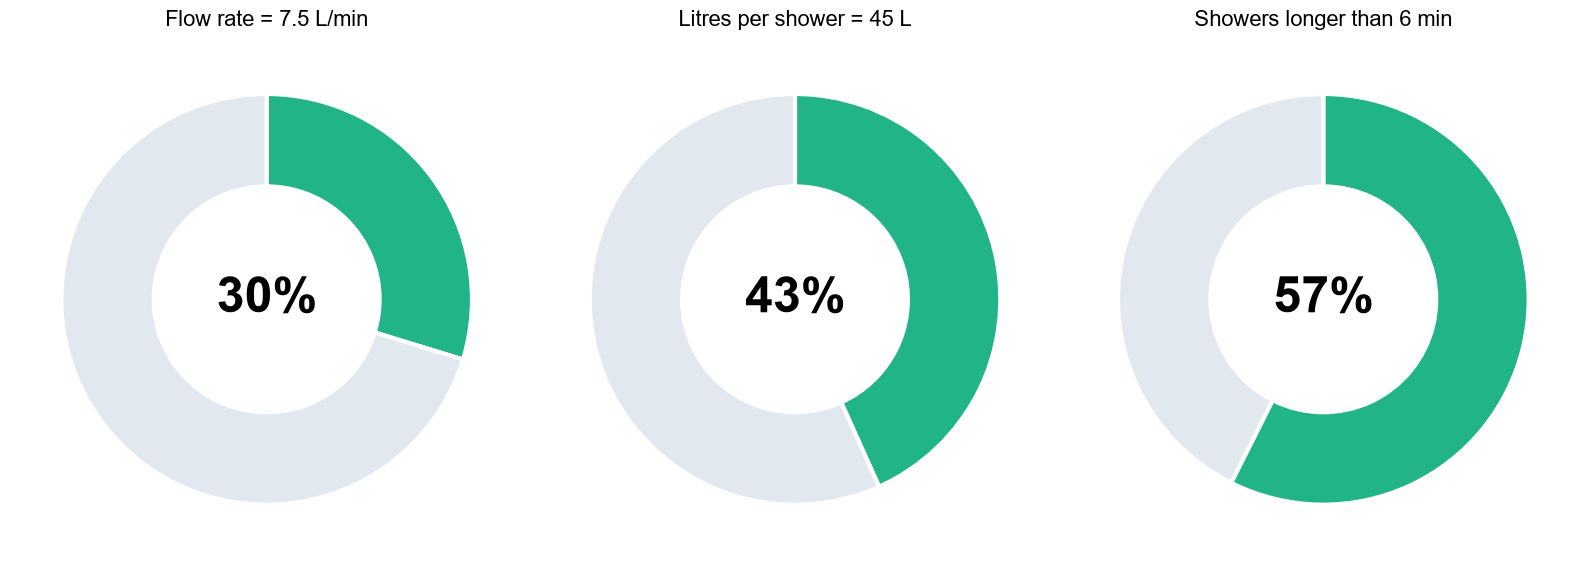

In [217]:
save = False
save_dir = 'figures'

green, light = '#20B486', '#E2E8F0'
plt.rcParams['font.family'] = 'Arial'

# the three boundary conditions, reusing flow_lpm / events_hot
dn_flow_above = flow_lpm > eff_flow_lpm
dn_litres_above = events_hot['total_l'] > cap_l
dn_length_above = events_hot['intervals'] >= 2      # >= 2 readings is the proxy for > 6 min

dn_panels = [
    (f'Flow rate = {eff_flow_lpm} L/min',      dn_flow_above),
    (f'Litres per shower = {cap_l} L',         dn_litres_above),
    (f'Showers longer than {shower_min} min',  dn_length_above),
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
for ax, (title, flag) in zip(axes, dn_panels):
    total_pct = pd.Series(np.asarray(flag), dtype=bool).mean() * 100

    ax.pie([total_pct, 100 - total_pct],
           colors=[green, light], startangle=90, counterclock=False,
           wedgeprops=dict(width=0.45, edgecolor='white', linewidth=3))
    ax.text(0, 0, f'{total_pct:.0f}%', ha='center', va='center', fontsize=36, fontweight='bold')
    ax.set_title(title, fontsize=16, pad=12)

plt.tight_layout()
if save:
    os.makedirs(save_dir, exist_ok=True)
    fig.savefig(f'{save_dir}/efficiency_donuts.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

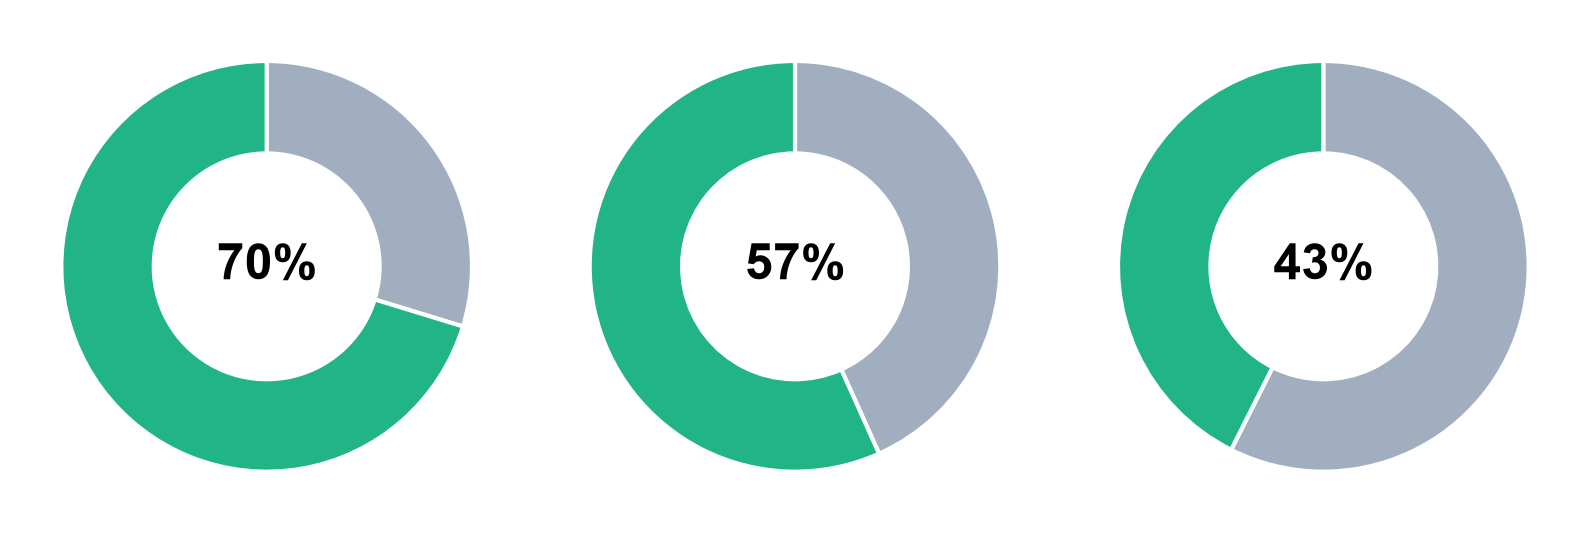

In [218]:
save = False
save_dir = 'figures'

green, light = '#20B486', '#A0AEC0'
plt.rcParams['font.family'] = 'Arial'

# the three boundary conditions, reusing flow_lpm / events_hot
dn_flow_above = flow_lpm > eff_flow_lpm
dn_litres_above = events_hot['total_l'] > cap_l
dn_length_above = events_hot['intervals'] >= 2      # >= 2 readings is the proxy for > 6 min

dn_panels = [dn_flow_above, dn_litres_above, dn_length_above]

fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))
for ax, flag in zip(axes, dn_panels):
    above_pct = pd.Series(np.asarray(flag), dtype=bool).mean() * 100
    green_pct = 100 - above_pct                     # share within the boundary (green part)

    ax.pie([above_pct, green_pct],
           colors=[light, green], startangle=90, counterclock=False,
           wedgeprops=dict(width=0.45, edgecolor='white', linewidth=3))
    ax.text(0, 0, f'{green_pct:.0f}%', ha='center', va='center', fontsize=36, fontweight='bold')

plt.tight_layout()
if save:
    os.makedirs(save_dir, exist_ok=True)
    fig.savefig(f'{save_dir}/efficiency_donuts.png', dpi=300, bbox_inches='tight', transparent=True)
plt.show()

### 2.5 The scenario definition at a glance

In [219]:
scenario_definition = pd.DataFrame(
    {
        'value': [f'{flow_reduction:.0%}', f'{shower_min} min', f'{cap_l} L', f'{cap_hot} L'],
        'basis in our data': [
            f'flow in longer showers: 90th percentile {current_flow_lpm:.1f} L/min, down to {eff_flow_lpm} L/min is {flow_derived:.0%}',
            f'{(events_hot["intervals"] >= 2).mean():.0%} of the showers have 2 or more readings, estimated average {est_minutes:.1f} min of running water, the best rooms use {best_volumes.mean() / eff_flow_lpm:.0f} min at the efficient flow',
            f'{(events_hot["total_l"] > cap_l).mean():.0%} of the showers are above it, the best rooms keep 75% of their showers under {best_volumes.quantile(0.75):.0f} L',
            f'hot share {hot_share_overall:.0%}, stable across periods ({period_view["hot_share_%"].min():.0f}-{period_view["hot_share_%"].max():.0f}%)'
        ],
        'basis in literature': [
            'normal heads 10-15 L/min, water saving heads 6-9 L/min',
            'typical durations in the sources are 6-11 min, 6 min as a short shower',
            'efficient head x 6 min = 45 L, below 40 L counts as frugal',
            'none, derived from cap_l'
        ],
        'confidence': ['medium-high', 'medium', 'medium', 'medium (data informed)']
    },
    index=['flow_reduction', 'shower_min', 'cap_l', 'cap_hot']
)
scenario_definition

,value,basis in our data,basis in literature,confidence
flow_reduction,25%,flow in longer showers: 90th percentile 10.3 L...,"normal heads 10-15 L/min, water saving heads 6...",medium-high
shower_min,6 min,"57% of the showers have 2 or more readings, es...","typical durations in the sources are 6-11 min,...",medium
cap_l,45 L,"43% of the showers are above it, the best room...","efficient head x 6 min = 45 L, below 40 L coun...",medium
cap_hot,30 L,"hot share 67%, stable across periods (66-68%)","none, derived from cap_l",medium (data informed)


## 3. Applying the scenario

### 3### 3.1 Applying the scenario to every shower

Each shower is changed in three steps: (1) the flow reduction scales the shower, (2) the length limit caps it at `cap_l`, (3) the hot part is its usual hot share of the new total, capped at `cap_hot`. The number of showers does not change, only the litres per shower..1 Build-up

In [220]:
# the cap must follow from the minute and flow definition in 2.5
assert cap_l == round(eff_flow_lpm * shower_min), "cap_l no longer matches shower_min x efficient flow"

def run_scenario(flow_cut, cap, cap_hot_l):
    total = (events_hot['total_l'] * (1 - flow_cut)).clip(upper=cap)
    hot = (total * hot_share).clip(upper=cap_hot_l)
    cold = total * (1 - hot_share)
    return pd.DataFrame({'scenario_hot_l': hot,
                         'scenario_cold_l': cold,
                         'scenario_total_l': hot + cold})

# apply once with the values defined in 2.5
events_hot[['scenario_hot_l', 'scenario_cold_l', 'scenario_total_l']] = run_scenario(flow_reduction, cap_l, cap_hot)
events_hot['saved_l'] = events_hot['total_l'] - events_hot['scenario_total_l']

applied = pd.Series({
    'showers': len(events_hot),
    'observed_m3': events_hot['total_l'].sum() / 1000,
    'scenario_m3': events_hot['scenario_total_l'].sum() / 1000,
    'saved_m3': events_hot['saved_l'].sum() / 1000,
    'saved_%': events_hot['saved_l'].sum() / events_hot['total_l'].sum() * 100,
    'avg_observed_l': events_hot['total_l'].mean(),
    'avg_scenario_l': events_hot['scenario_total_l'].mean(),
}).round(1)
applied

showers           16305.0
observed_m3         908.1
scenario_m3         439.6
saved_m3            468.5
saved_%              51.6
avg_observed_l       55.7
avg_scenario_l       27.0
dtype: float64

### 3.2 Build-up: what each lever adds

The three levers are applied one after another, so the last row is the full scenario from 2.5.

In [221]:
no_cap = 10**6
steps = {
    'observed':                               (0,              no_cap, no_cap),
    f'+ flow reduction ({flow_reduction:.0%})': (flow_reduction, no_cap, no_cap),
    f'+ {shower_min} min limit ({cap_l} L)':   (flow_reduction, cap_l,  no_cap),
    f'+ hot cap ({cap_hot} L)':                (flow_reduction, cap_l,  cap_hot),
}

build_up = pd.DataFrame(index=steps.keys(), columns=['water_m3', 'hot_water_m3'], dtype=float)
for name, (fc, cap, ch) in steps.items():
    res = run_scenario(fc, cap, ch)
    build_up.loc[name, 'water_m3'] = res['scenario_total_l'].sum() / 1000
    build_up.loc[name, 'hot_water_m3'] = res['scenario_hot_l'].sum() / 1000

build_up['water_saved_%'] = (1 - build_up['water_m3'] / build_up.iloc[0]['water_m3']) * 100
build_up['hot_saved_%'] = (1 - build_up['hot_water_m3'] / build_up.iloc[0]['hot_water_m3']) * 100
build_up.round(1)

,water_m3,hot_water_m3,water_saved_%,hot_saved_%
observed,908.1,610.5,0.0,0.0
+ flow reduction (25%),681.1,457.9,25.0,25.0
+ 6 min limit (45 L),449.1,300.5,50.5,50.8
+ hot cap (30 L),439.6,291.0,51.6,52.3


In [222]:
obs = events_hot['total_l'].sum()
saving = lambda litres: (1 - litres.sum() / obs) * 100

# 1) flow alone: reduction to the efficient flow
flow_alone = saving(run_scenario(flow_reduction, no_cap, no_cap)['scenario_total_l'])

# 2) litres alone: 45 L cap on the observed showers
cap_alone = saving(run_scenario(0, cap_l, no_cap)['scenario_total_l'])

# 3) length alone: running time limited to shower_min (minutes estimated from the readings)
est_min = (events_hot['intervals'] - 1).clip(lower=0) * 10
length_alone = saving(events_hot['total_l'] * (shower_min / est_min.replace(0, np.nan)).clip(upper=1).fillna(1))

# combined scenario (flow + cap; length is the same limit as the cap, so it is not added again)
combined = saving(run_scenario(flow_reduction, cap_l, no_cap)['scenario_total_l'])

print(f"Flow rate = {eff_flow_lpm} L/min:       {flow_alone:.0f}%")
print(f"Litres per shower = {cap_l} L:      {cap_alone:.0f}%")
print(f"Showers longer than {shower_min} min:  {length_alone:.0f}%")
print(f"AquaSave scenario (combined):  {combined:.0f}%")

Flow rate = 7.5 L/min:       25%
Litres per shower = 45 L:      44%
Showers longer than 6 min:  46%
AquaSave scenario (combined):  51%


**Observations**
- Flow reduction alone saves 25.0% by construction. The 6 min limit (45 L) raises this to 50.5% because it cuts the long showers, which hold most of the water (43.3% of showers are above 45 L, with 79.3% of the litres). The hot cap adds about one more point, to 51.6%.
- The hot cap matters little because the length limit already cuts most of the hot water.

### 3.3 Where do the savings fall? Time of day

In [223]:
period_result = events_hot.groupby('period', observed=True).agg(
    showers=('total_l', 'size'),
    observed_l=('total_l', 'sum'),
    scenario_l=('scenario_total_l', 'sum'),
    observed_hot_l=('hot_l', 'sum'),
    scenario_hot_l=('scenario_hot_l', 'sum'),
)
period_result['water_saved_%'] = (1 - period_result['scenario_l'] / period_result['observed_l']) * 100
period_result['share_of_saved_water_%'] = (period_result['observed_l'] - period_result['scenario_l']) / (period_result['observed_l'].sum() - period_result['scenario_l'].sum()) * 100
period_result['share_of_saved_hot_%'] = (period_result['observed_hot_l'] - period_result['scenario_hot_l']) / (period_result['observed_hot_l'].sum() - period_result['scenario_hot_l'].sum()) * 100
period_result['share_of_showers_%'] = period_result['showers'] / period_result['showers'].sum() * 100
period_result.round(1)

,showers,observed_l,scenario_l,observed_hot_l,scenario_hot_l,water_saved_%,share_of_saved_water_%,share_of_saved_hot_%,share_of_showers_%
period,,,,,,,,,
night,547,30103.0,14086.0,20197.0,9276.0,53.2,3.4,3.4,3.4
morning,6086,281458.0,153831.0,186534.0,100999.5,45.3,27.2,26.8,37.3
afternoon,4391,275483.0,119730.5,184471.0,79013.8,56.5,33.2,33.0,26.9
evening,5281,321048.0,151966.1,219267.0,101684.1,52.7,36.1,36.8,32.4


- with the scenario the average shower falls from 55.7 L to 27.0 L. The best rooms of this building already average 29.4 L, so the scenario ends 2.4 L below that level: it is about as ambitious as bringing every room to the level of the best quartile
- private bathrooms go from 41.1 to 22.6 L, shared ones from 68.0 to 30.6 L: the shared bathrooms carry most of the saving
- the best rooms are private bathrooms that already use little, so the scenario asks them to go further than they do today, which is a sign that the full scenario is on the ambitious side or may be even questionable

### 3.4 Private and shared bathrooms, and the internal benchmark

In [224]:
bathroom_result = events_hot.groupby('bathroom').agg(
    showers=('total_l', 'size'),
    avg_observed_l=('total_l', 'mean'),
    avg_scenario_l=('scenario_total_l', 'mean'),
)
bathroom_result['water_saved_%'] = (1 - bathroom_result['avg_scenario_l'] / bathroom_result['avg_observed_l']) * 100
bathroom_result.round(1)

,showers,avg_observed_l,avg_scenario_l,water_saved_%
bathroom,,,,
private,7444,41.1,22.6,45.0
shared,8861,68.0,30.6,54.9


In [225]:
# internal benchmark: the scenario average against the best rooms observed in 2.x
print(f"Scenario average per shower: {events_hot['scenario_total_l'].mean():.1f} L")
print(f"Best rooms today (observed):  {best_volumes.mean():.1f} L")

Scenario average per shower: 27.0 L
Best rooms today (observed):  29.4 L


### 3.5 Check: flow reduction per room instead of the same % everywhere

The scenario uses one flow reduction for all rooms. Here each room is cut only as far as its own p90 flow is above the efficient flow, and rooms already at or below 7.5 L/min are left unchanged.

In [226]:
room_cut = (1 - eff_flow_lpm / room_flow['p90']).clip(lower=0)
cut_per_shower = events_hot['room_number'].map(room_cut).fillna(flow_reduction)

tot = (events_hot['total_l'] * (1 - cut_per_shower)).clip(upper=cap_l)
hot = (tot * hot_share).clip(upper=cap_hot)
saved_room_cut = (1 - (hot + tot * (1 - hot_share)).sum() / events_hot['total_l'].sum()) * 100

print(f"Same {flow_reduction:.0%} everywhere:  {applied['saved_%']:.1f}% saved")
print(f"Flow cut per room:     {saved_room_cut:.1f}% saved")

Same 25% everywhere:  51.6% saved
Flow cut per room:     49.6% saved


**Observation:** the result moves by about two points (51.6% vs 49.6%), so the single 25% flow reduction is a reasonable simplification.

### 3.6 Sensitivity: flow reduction and shower length

The cap follows the shower length (minutes × 7.5 L/min). The hot cap follows the cap (cap × overall hot share).

In [227]:
def saving_pct(flow_cut, minutes):
    cap = round(eff_flow_lpm * minutes)
    res = run_scenario(flow_cut, cap, round(cap * hot_share_overall))
    return (1 - res['scenario_total_l'].sum() / events_hot['total_l'].sum()) * 100

flow_cuts = [0, 0.15, 0.25, 0.35]
minutes = [4, 5, 6, 7, 8, 10_000]   # last = no length limit

sensitivity = pd.DataFrame(
    {f'{m} min ({round(eff_flow_lpm*m)} L)' if m < 10_000 else 'no limit':
        [saving_pct(fc, m) for fc in flow_cuts] for m in minutes},
    index=[f'flow cut {fc:.0%}' for fc in flow_cuts])
sensitivity.round(1)

,4 min (30 L),5 min (38 L),6 min (45 L),7 min (52 L),8 min (60 L),no limit
flow cut 0%,58.9,51.0,45.6,40.4,35.5,0.0
flow cut 15%,60.7,53.7,48.9,44.4,40.3,15.0
flow cut 25%,62.2,55.8,51.6,47.7,44.1,25.0
flow cut 35%,64.1,58.4,54.8,51.5,48.6,35.0


### AquaSave savings

In [228]:
years = (events_hot['start'].max() - events_hot['start'].min()).days / 365.25

obs_m3 = events_hot['total_l'].sum() / 1000
sav_m3 = events_hot['saved_l'].sum() / 1000
obs_hot = events_hot['hot_l'].sum() / 1000
sav_hot = (events_hot['hot_l'] - events_hot['scenario_hot_l']).sum() / 1000

print(f"Rooms: {events_hot['room_number'].nunique()}, showers: {len(events_hot):,}, period: {years:.2f} years")
print(f"Shower water: {obs_m3:,.1f} m³ -> {obs_m3 - sav_m3:,.1f} m³")
print(f"AquaSave saves {sav_m3:,.1f} m³ ({sav_m3 / obs_m3:.1%}), about {sav_m3 / years:,.1f} m³ per year")
print(f"Hot water saved: {sav_hot:,.1f} m³ ({sav_hot / obs_hot:.1%}), about {sav_hot / years:,.1f} m³ per year")
print(f"Per shower: {events_hot['total_l'].mean():.1f} L -> {events_hot['scenario_total_l'].mean():.1f} L")

Rooms: 11, showers: 16,305, period: 3.09 years
Shower water: 908.1 m³ -> 439.6 m³
AquaSave saves 468.5 m³ (51.6%), about 151.8 m³ per year
Hot water saved: 319.5 m³ (52.3%), about 103.5 m³ per year
Per shower: 55.7 L -> 27.0 L


## 4. Summary: how the scenario was built
1. **Baseline** from the shower events: 16,305 showers, average 55.7 L, hot share 67.2%
2. **Time of day**: hot mix and parameters are the same in all periods, the morning showers are smaller, so the savings sit mostly in the afternoon and evening
3. **Rooms**: differences between rooms come mainly from the flow, so the flow reduction is the main lever, the duration lever is the cap
4. **Parameters**: flow_reduction 25% (data and literature agree), cap_l 45 L (literature plus the best rooms, strong assumption), cap_hot 30 L (derived), delta_t 45 K (literature only)
5. **Result**: 25.0% (flow only, careful case) / 50.5% (with total cap, central case) / 51.6% (full scenario) of the shower water. The full scenario is more ambitious than the best rooms of the building, so the careful and central case are better to present first

Limits: the unit of `value` still has to be confirmed, durations are only known in steps of 10 min, there is no occupancy data (litres per person cannot be computed), and the scenario applies the levers to the observed showers, it does not predict how residents would behave.

## Sources
Checked on 5 October 2026. Secondary sources should be replaced by primary ones before anything is published.

- Verbraucherzentrale NRW, *Warmwasser im Alltag sparen: So geht's* (as of 1 Sep 2025): normal shower heads 10-12 L/min, water saving heads below 9 L/min, very good ones about 6 L/min. https://www.verbraucherzentrale.nrw/wissen/energie/heizen-und-warmwasser/warmwasser-im-alltag-sparen-so-gehts-17752
- co2online, *Wasserverbrauch beim Duschen und Baden*: usual shower heads 12-15 L/min, 8 L/min or less counts as low flow, average shower duration 11 min (Hansgrohe study). https://www.co2online.de/energie-sparen/wasser-sparen/wasserverbrauch/wasserverbrauch-duschen/
- Umweltbundesamt, *Warmwasser*: usual shower heads 12-15 L/min, water saving ones 6-9 L/min, hygiene requirement of at least 60 C. https://umweltbundesamt.de/print/23201 (print view)
- OEKO-TEST, *Was kostet eigentlich einmal Duschen?*: 40-150 L per shower, below 40 L is frugal, typical duration about 8-10 min (no current figures). https://www.oekotest.de/freizeit-technik/was-kostet-eigentlich-einmal-duschen-50-cent-1-oder-2-euro_13195_1.html
- *Einfach klimagerechter leben in Bayern*, chapter Wasser: usual shower heads 12-15 L/min, water saving variant 6-8 L/min. https://verbraucher.org/media/file/2401.Einfach-klimagerechter-leben-in-Bayern_Kapitel_Wasser.pdf
- DVGW worksheet W 551 (60 C at the water heater outlet, 55 C in the circulation), as summarised in SBZ, a secondary source: https://www.sbz-online.de/sites/default/files/ulmer/de-sbz/document/file_152904.pdf
- Kaufland blog citing Statista (6 min and 44 L per shower), a retail blog, weakest source, only used to show the low end of the duration range: https://www.kaufland.de/i/nachhaltig-leben/wasserverbrauch-duschen/~UOrB9X8QswAyqWOAt6vUR/

saved: figures\shower_distribution.png


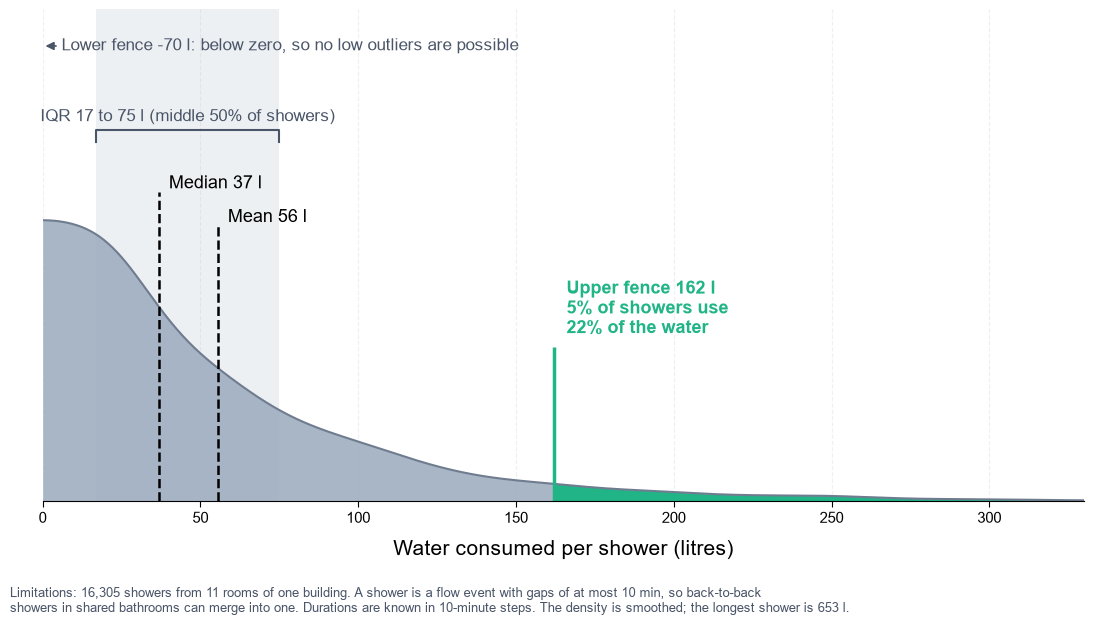

mean 55.7 l, median 37.0 l, Q1 17 l, Q3 75 l, IQR 58 L
lower fence -70 l (below 0), upper fence 162 l
885 showers (5.4%) above the upper fence = 22.4% of the water


In [229]:
# Plotting for presentation
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = ["Arial"]
green, grey, ink = "#20B486", "#A0AEC0", "#000000"

save, save_dir = True, "figures"
show_notes = True                 # small footnote with the limitations

v = events_hot['total_l']         # litres per shower, rooms with a hot sensor
mean, median = v.mean(), v.median()
q1, q3 = v.quantile([.25, .75])
iqr = q3 - q1
upper_fence, lower_fence = q3 + 1.5 * iqr, q1 - 1.5 * iqr          # lower fence is below 0: no low outliers possible
above = v > upper_fence

# smooth density, reflected at 0 because litres cannot be negative
x = np.linspace(0, 330, 700)
kde = gaussian_kde(v, bw_method=0.2)
dens = kde(x) + kde(-x)

fig, ax = plt.subplots(figsize=(11, 5.8))
ax.axvspan(q1, q3, color=grey, alpha=0.18, lw=0)                     # middle 50 % of showers (IQR)
ax.fill_between(x, dens, color=grey, alpha=0.9, lw=0)
ax.fill_between(x, dens, where=x >= upper_fence, color=green, lw=0)  # outliers above the fence
ax.plot(x, dens, color="#6F7C8F", lw=1.5)
ymax = dens.max()

ax.vlines(median, 0, ymax * 1.10, color=ink, lw=1.8, ls="--")
ax.text(median + 3, ymax * 1.10, f"Median {median:.0f} l", fontsize=13, va="bottom", color=ink)
ax.vlines(mean, 0, ymax * 0.98, color=ink, lw=1.8, ls="--")
ax.text(mean + 3, ymax * 0.98, f"Mean {mean:.0f} l", fontsize=13, va="bottom", color=ink)

# IQR bracket
yb = ymax * 1.32
ax.plot([q1, q1, q3, q3], [yb - ymax * 0.04, yb, yb, yb - ymax * 0.04], color="#4A5568", lw=1.5)
ax.text((q1 + q3) / 2, yb + ymax * 0.02, f"IQR {q1:.0f} to {q3:.0f} l (middle 50% of showers)", fontsize=12, color="#4A5568", ha="center", va="bottom")

# fences
ax.vlines(upper_fence, 0, ymax * 0.55, color=green, lw=2.5)
ax.text(upper_fence + 4, ymax * 0.58, f"Upper fence {upper_fence:.0f} l\n{above.mean() * 100:.0f}% of showers use\n{v[above].sum() / v.sum() * 100:.0f}% of the water",
        fontsize=13, va="bottom", color=green, fontweight="bold")
ax.annotate(f"Lower fence {lower_fence:.0f} l: below zero, so no low outliers are possible", xy=(0, ymax * 1.62), xytext=(6, ymax * 1.62),
            fontsize=12, color="#4A5568", va="center", arrowprops=dict(arrowstyle="-|>", color="#4A5568", lw=1.2))

ax.set_xlim(0, 330)
ax.set_ylim(0, ymax * 1.75)
ax.set_yticks([])
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(ink)
ax.tick_params(axis="x", colors=ink, labelsize=11, length=4)
ax.xaxis.grid(True, linestyle="--", linewidth=0.85, alpha=0.18)
ax.set_axisbelow(True)
ax.set_xlabel("Water consumed per shower (litres)", fontsize=15, labelpad=10)

if show_notes:
    fig.text(0.01, -0.02,
             f"Limitations: {len(v):,} showers from 11 rooms of one building. A shower is a flow event with gaps of at most 10 min, so back-to-back\n"
             f"showers in shared bathrooms can merge into one. Durations are known in 10-minute steps. The density is smoothed; the longest shower is {v.max():.0f} l.",
             fontsize=9.5, color="#4A5568", va="top")

fig.tight_layout()
if save:
    os.makedirs(save_dir, exist_ok=True)
    path = os.path.join(save_dir, "shower_distribution.png")
    fig.savefig(path, dpi=300, bbox_inches="tight")
    print(f"saved: {path}")
plt.show()
plt.close(fig)

print(f"mean {mean:.1f} l, median {median:.1f} l, Q1 {q1:.0f} l, Q3 {q3:.0f} l, IQR {iqr:.0f} L")
print(f"lower fence {lower_fence:.0f} l (below 0), upper fence {upper_fence:.0f} l")
print(f"{above.sum():,} showers ({above.mean() * 100:.1f}%) above the upper fence = {v[above].sum() / v.sum() * 100:.1f}% of the water")

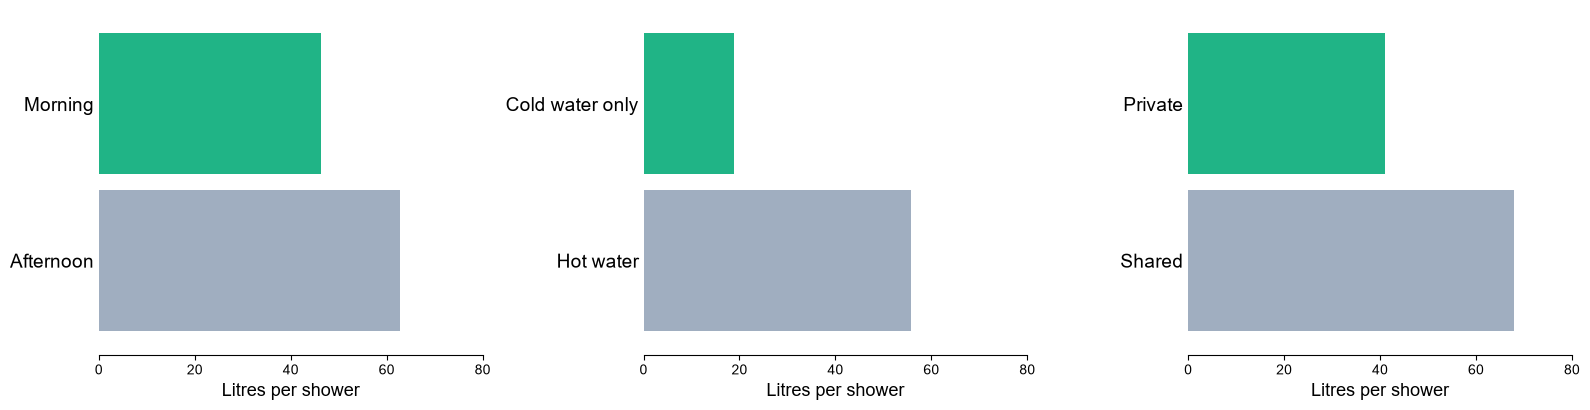

In [230]:
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial']
green, grey = '#20B486', '#A0AEC0'

# averages in litres per shower (same data and rules as the earlier slides)
per = events_hot.assign(period=events_hot['period'].astype(str)).groupby('period')['total_l'].mean()
bath = events_hot.groupby(events_hot['bathroom'].astype(str).str.lower().str.contains('shared|share|gemein').map({True: 'Shared', False: 'Private'}))['total_l'].mean()
warm_l = events_hot['total_l'].mean()
cold_l = events[~events['room_number'].isin(hot_rooms)]['cold_l'].mean()

panels = [
    (['Morning', 'Afternoon'],         [per['morning'], per['afternoon']]),
    (['Cold water only', 'Hot water'], [cold_l, warm_l]),
    (['Private', 'Shared'],            [bath['Private'], bath['Shared']]),
]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharex=True)
for ax, (labels, vals) in zip(axes, panels):
    lo = int(np.argmin(vals))
    colors = [green if i == lo else grey for i in range(2)]       # green = the lower-consumption option
    ax.barh([0, 1], vals, height=0.9, color=colors, edgecolor='none')
    ax.set_xlim(0, 80); ax.set_ylim(1.6, -0.6)
    ax.xaxis.set_major_locator(MultipleLocator(20))
    ax.set_yticks([0, 1]); ax.set_yticklabels(labels, fontsize=14); ax.tick_params(axis='y', length=0)
    ax.set_xlabel('Litres per shower', fontsize=13)
    for s in ('top', 'right', 'left'): ax.spines[s].set_visible(False)

plt.tight_layout()
save, save_dir = True, 'figures'
if save:
    import os; os.makedirs(save_dir, exist_ok=True)
    fig.savefig(f'{save_dir}/why_these_factors.png', dpi=200, bbox_inches='tight', transparent=False)
plt.show()

## AquaSave the App

### Lenses

In [231]:
# lenses grouped into sections people relate to
# litres_per_unit = litres of water behind one unit; forced_period = shortest sensible period ('' = free)
# kind: 'literal' = the water itself (drunk, used, needed)
#       'water behind' = virtual water used to make the product (not literally the saved water)
lenses = pd.DataFrame([
    # section,           lens,               kind,           unit,                                   unit_plural,                                litres_per_unit,   forced, icon,     source
    ['AquaSave shower',  'AquaSave showers', 'literal',      f'AquaSave shower ({shower_min} min at {eff_flow_lpm} L/min)',
                                                              f'AquaSave showers ({shower_min} min at {eff_flow_lpm} L/min)',                   cap_l,             '',     'shower', 'scenario definition: shower_min x efficient flow = cap_l'],
    ['AquaSave shower',  'Shower minutes',   'literal',      'minute of showering',                  'minutes of showering',                     current_flow_lpm,  '',     'clock',  'flow measured in the data (p90 of the shower flow)'],

    ['Medical',          'Dialysis',         'literal',      'dialysis session',                     'dialysis sessions',                        120,               '',     'drip',   'hemodialysis: about 500 mL/min of dialysate over about 4 h = about 120 L per session (typical value, verify with a clinical source)'],

    ['Data centre',      'Data centre',      'literal',      'kWh of data-centre computing',         'kWh of data-centre computing',             1.8,               '',     'server', 'average water usage effectiveness of data centres, about 1.8 L per kWh, Uptime Institute (varies strongly by site, verify)'],

    ['Pets',             'Dog',              'literal',      'day of drinking water for a dog (20 kg)',  'days of drinking water for a dog (20 kg)', 1.3,            '',     'dog',    'about 60-70 mL per kg body weight per day (rule of thumb, verify with a vet source)'],
    ['Pets',             'Cat',              'literal',      'day of drinking water for a cat (4.5 kg)', 'days of drinking water for a cat (4.5 kg)', 0.25,           '',     'cat',    'about 50 mL per kg body weight per day (rule of thumb, includes water in food, verify)'],
    ['Pets',             'Aquarium',         'literal',      'aquarium filling',                     'aquarium fillings',                        63,                '',     'tank',   'typical home aquarium of about 60 L (assumption, size varies)'],

    ['Sports',           'Running',          'literal',      'km run',                               'km run',                                   0.07,              '',     'track',  'fluid a runner drinks per km (marathon 42.2 km = 2.95 L), Marathon Hamburg'],

    ['Bakery', 'Pretzel', 'water behind', 'Brezel (about 100 g)', 'Brezeln (about 100 g)', 130, '', 'pretzel',     'virtual water of bread, about 1,300 L per kg, Hoekstra 2008 (a Brezel of about 100 g)'],
    ['Bakery',           'Bread',            'water behind', 'loaf of bread (500 g)',                'loaves of bread (500 g)',                  650,               'year', 'loaf',   'global average virtual water of bread, about 1,300 L per kg, Hoekstra 2008'],

    ['Ice cream',        'Ice cream',        'literal',      'scoop of ice cream (about 60 g)',      'scoops of ice cream (about 60 g)',         0.035,             '',     'icecream', 'ice cream is about 60% water, a Kugel of about 60 g holds about 35 mL (assumption)'],

    ['Sweets & drinks',  'Coffee',           'water behind', 'cup of coffee',                        'cups of coffee',                           140,               'year', 'cup',    'global average virtual water of one cup, about 140 L, Hoekstra 2008'],
    ['Sweets & drinks',  'Chocolate',        'water behind', 'bar of chocolate (100 g)',             'bars of chocolate (100 g)',                2400,              'year', 'bar',    'global average virtual water of chocolate, about 24,000 L per kg (older figure), Hoekstra 2008'],

    ['Plants',           'Tree watering',    'literal',      'tree watering',                        'tree waterings',                           60,                '',     'tree',   'about 60 L per watering of a young street tree, BUND Naturschutz'],
    ['Plants',           'Tomato plant',     'literal',      'watering of a tomato plant',           'waterings of a tomato plant',              2.5,               '',     'plant',  'about 2-3 L per plant and watering in summer (rule of thumb, verify)'],

    ['Household',        'Basic needs',      'literal',      'day of basic water for one person',    'days of basic water for one person',       20,                '',     'drop',   'WHO minimum for drinking, cooking and hygiene, about 20 L per person per day'],
    ['Household',        'Household use',    'literal',      'day of average household use of one person', 'days of average household use of one person', 121,       '',     'drop',   'German average of about 121 L per person per day, co2online'],
    ['Household',        'Bathtubs',         'literal',      'bathtub filling',                      'bathtub fillings',                         150,               'year', 'tub',    'a filled bathtub, about 150 L, co2online'],
], columns=['section', 'lens', 'kind', 'unit', 'unit_plural', 'litres_per_unit', 'forced_period', 'icon', 'source'])

# the period the user sees: one day, a week, a month or a year of showers, number of showers per day unchanged
periods = {'day': 1, 'week': 7, 'month': 30, 'year': 365}
min_units = 10    # a lens needs at least this many units before it is shown in a period

def lens_view(lens, saved_l_per_day, period=None):
    row = lenses.set_index('lens').loc[lens]
    note = ''
    if row['forced_period']:
        chosen = row['forced_period']
        if period not in (None, 'auto', chosen):
            note = f'{lens} is always shown per {chosen}: a single {row["unit"]} needs a lot of water.'
    elif period in periods:
        chosen = period
    else:
        # shortest period that gives at least min_units
        chosen = next((p for p, d in periods.items() if saved_l_per_day * d / row['litres_per_unit'] >= min_units), 'year')
    litres = saved_l_per_day * periods[chosen]
    units = litres / row['litres_per_unit']
    return {'section': row['section'], 'lens': lens, 'kind': row['kind'], 'period': chosen, 'litres': litres, 'units': units,
            'unit': row['unit'] if round(units) == 1 else row['unit_plural'], 'unit_plural': row['unit_plural'],
            'icon': row['icon'], 'note': note}

def section_view(section, saved_l_per_day, period=None):
    """all lenses of one section, e.g. section_view('Pets', 415)"""
    names = lenses.loc[lenses['section'] == section, 'lens']
    return [lens_view(n, saved_l_per_day, period) for n in names]

sections = list(dict.fromkeys(lenses['section']))   # keeps the order above
# shown first in the app, one lens per default section
default_lenses = ['AquaSave showers', 'Tomato plant', 'Running']

def default_view(saved_l_per_day, period=None):
    return [lens_view(n, saved_l_per_day, period) for n in default_lenses]

In [232]:
#lenses

In [233]:
# the water saved per shower under the AquaSave scenario (level 3), one shower per day
saving_per_shower = (events_hot['total_l'] - events_hot['scenario_total_l']).mean()

overview = pd.DataFrame([lens_view(l, saving_per_shower) for l in lenses['lens']])
overview['units'] = overview['units'].round(1)
overview['litres'] = overview['litres'].round(0)
overview[['lens', 'kind', 'period', 'litres', 'units', 'unit']]

,lens,kind,period,litres,units,unit
0,AquaSave showers,literal,month,862.0,19.2,AquaSave showers (6 min at 7.5 L/min)
1,Shower minutes,literal,week,201.0,19.5,minutes of showering
2,Dialysis,literal,year,10487.0,87.4,dialysis sessions
3,Data centre,literal,day,29.0,16.0,kWh of data-centre computing
4,Dog,literal,day,29.0,22.1,days of drinking water for a dog (20 kg)
5,Cat,literal,day,29.0,114.9,days of drinking water for a cat (4.5 kg)
6,Aquarium,literal,month,862.0,13.7,aquarium fillings
7,Running,literal,day,29.0,410.5,km run
8,Pretzel,water behind,year,10487.0,80.7,Brezeln (about 100 g)
9,Bread,water behind,year,10487.0,16.1,loaves of bread (500 g)


In [234]:
app_data = {
    'shower_litres': events_hot['total_l'].round(1).tolist(),
    'current_flow_lpm': round(float(current_flow_lpm), 1),
    'defaults': {'flow_reduction': float(flow_reduction), 'shower_min': float(shower_min), 'eff_flow_lpm': float(eff_flow_lpm)},
    'n_showers': int(len(events_hot)),
    'n_rooms': int(events_hot['room_number'].nunique()),
    'years': round((events_hot['start'].max() - events_hot['start'].min()).days / 365.25, 2),
}
with open('app_data.json', 'w') as f:
    json.dump(app_data, f)

lenses.to_csv('lenses.csv', index=False)

# the logo is the file called "Logo" (with or without extension) next to the notebook
print('logo found:', [p for p in glob.glob('Logo*') + glob.glob('logo*')])

logo found: ['Logo.png', 'Logo.png']


In [235]:
import json, glob

# warm showers: rooms with a hot sensor; cold showers: the rooms without one (R011, R012)
cold_events = events[~events['room_number'].isin(hot_rooms)]

# measured flow per shower, from the flow estimation in 2.x (only showers with 3 or more readings have one)
flow_by_event = flow_lpm.groupby(middle['event_id'].values).mean()

def to_rows(df, kind):
    litres = df['total_l'] if 'total_l' in df.columns else df['cold_l']
    if 'bathroom' in df.columns:
        b = df['bathroom'].astype(str).str.lower()
        bath = np.where(b.str.contains('shared|share|gemein'), 'shared', 'private')
    else:
        bath = 'private'
    period = df['period'].astype(str).str.lower().values if 'period' in df.columns else 'unknown'
    flow = pd.Series(df.index, index=df.index).map(flow_by_event).values if kind == 'warm' else np.nan
    return pd.DataFrame({'litres': litres.round(1).values,
                         'est_min': (10 * (df['intervals'] - 1).clip(lower=0)).values,
                         'kind': kind, 'bathroom': bath, 'period': period, 'flow': flow})

showers = pd.concat([to_rows(events_hot, 'warm'), to_rows(cold_events, 'cold')], ignore_index=True)
showers.to_csv('showers.csv', index=False)

with open('app_meta.json', 'w') as f:
    json.dump({'flow_reduction': float(flow_reduction), 'shower_min': float(shower_min), 'cap_l': int(cap_l),
               'current_flow_lpm': round(float(current_flow_lpm), 1)}, f)
lenses.to_csv('lenses.csv', index=False)

print(showers.groupby(['kind', 'bathroom']).size())
print(showers.groupby(['kind', 'period']).size())
print('showers with a flow value:', showers['flow'].notna().sum(), '| median flow:', round(showers['flow'].median(), 1))
print('logo:', glob.glob('Logo*') + glob.glob('logo*'))

kind  bathroom
cold  private     2127
warm  private     7444
      shared      8861
dtype: int64
kind  period   
cold  afternoon     791
      evening       784
      morning       468
      night          84
warm  afternoon    4391
      evening      5281
      morning      6086
      night         547
dtype: int64
showers with a flow value: 2764 | median flow: 5.2
logo: ['Logo.png', 'Logo.png']


### Building the app

In [ ]:
green, blue, grey = '#20B486', '#0A8BDD', '#A0AEC0'
TXT = 'var(--body-text-color, #1A202C)'              # follows light / dark mode
SUB = 'var(--body-text-color-subdued, #718096)'
BOX = 'var(--background-fill-secondary, #F7FAFC)'

# ---------- data exported from the notebook ----------
S = pd.read_csv('showers.csv')
S = S.dropna(subset=['litres', 'est_min']).reset_index(drop=True)
for _c, _v in (('period', ''), ('flow', np.nan), ('bathroom', 'private'), ('kind', 'warm')):   # older exports lack some columns
    if _c not in S.columns:
        S[_c] = _v
META = json.load(open('app_meta.json'))
LENSES = pd.read_csv('lenses.csv').fillna('')
TOPICS = list(dict.fromkeys(LENSES['section']))
LENS_BY_TOPIC = {t: list(LENSES.loc[LENSES['section'] == t, 'lens']) for t in TOPICS}
PERIODS = {'day': 1, 'week': 7, 'month': 30, 'year': 365}
MIN_UNITS = 10
ICONS = {'shower': '🚿', 'clock': '⏱️', 'drip': '💧', 'server': '🖥️', 'dog': '🐕', 'cat': '🐈', 'tank': '🐟',
         'track': '🏃', 'pretzel': '🥨', 'loaf': '🍞', 'icecream': '🍦', 'cup': '☕', 'bar': '🍫',
         'tree': '🌳', 'plant': '🍅', 'drop': '💧', 'tub': '🛁'}

# ---------- logo: white background made transparent, so it works in light and dark mode ----------
def load_logo(width=None, height=None):
    files = [p for p in glob.glob('[Ll]ogo*') if os.path.isfile(p)]
    if not files:
        return ''
    a = np.array(Image.open(files[0]).convert('RGBA')).astype(float)
    whiteness = a[..., :3].min(axis=2)
    a[..., 3] = np.minimum(a[..., 3], np.clip((245 - whiteness) * 6, 0, 255))
    img = Image.fromarray(a.astype('uint8'), 'RGBA')
    bbox = img.getchannel('A').point(lambda p: 255 if p > 10 else 0).getbbox()
    if bbox:
        img = img.crop(bbox)
    img.thumbnail((width or 4000, height or 4000))
    buf = io.BytesIO(); img.save(buf, format='PNG')
    return 'data:image/png;base64,' + base64.b64encode(buf.getvalue()).decode()

LOGO_BIG = load_logo(width=1000)
LOGO_SMALL = load_logo(height=140)

# ---------- scenario ----------
HOUSEHOLDS = ['Private house / bathroom', 'Shared bathroom']
KINDS = ['Cold showers only', 'Warm showers only', 'Both']

PERIODS_OF_DAY = ['No preference', 'Morning', 'Afternoon', 'Evening', 'Night']

# ---------- observations from the data, used as factors ----------
# Water per shower differs between warm and cold showers, private and shared bathrooms and times of day,
# while the shower length hardly changes. These differences are measured here once and applied as factors.
MIN_N = 30
def _has(df, p):
    return df['period'].astype(str).str.lower().str.contains(p.lower())

W, C = S[S['kind'] == 'warm'], S[S['kind'] == 'cold']
W_L = float(W['litres'].mean()) if len(W) else float(S['litres'].mean())            # warm litres per shower (reference)
W_M = float(W['est_min'].mean()) if len(W) else float(S['est_min'].mean())
SHARE_COLD = len(C) / max(len(S), 1)
K_COLD = float(C['litres'].mean() / W_L) if len(C) >= MIN_N and W_L > 0 else 1.0     # cold litres relative to warm
_cm = float(C['est_min'].mean()) if len(C) else 0.0
K_COLD_RATE = (float(C['litres'].mean()) / _cm) / (W_L / W_M) if len(C) >= MIN_N and _cm > 0 and W_M > 0 else K_COLD   # litres per minute
FLOW_WARM = W['flow'].dropna()

def group_factor(mask, col='litres', ref=None):
    """mean of the group relative to the warm reference; 1.0 if the group is too small"""
    g = W[mask(W)]
    if col == 'flow':
        g, ref = g['flow'].dropna(), (ref if ref is not None else FLOW_WARM.mean())
    else:
        g, ref = g['litres'], (ref if ref is not None else W_L)
    return float(g.mean() / ref) if len(g) >= MIN_N and ref and ref > 0 else 1.0

BATH_F = {h: group_factor(lambda d, h=h: d['bathroom'] == h) for h in ('private', 'shared')}
PER_F = {p: group_factor(lambda d, p=p: _has(d, p)) for p in PERIODS_OF_DAY[1:]}
FLOWOK = len(FLOW_WARM) >= MIN_N
print('--- AquaSave check ---')
print('showers by kind      :', S['kind'].value_counts().to_dict())
print('showers by bathroom  :', S['bathroom'].value_counts().to_dict())
print('showers by period    :', S['period'].astype(str).value_counts().to_dict())
print('warm-shower factors  : bathroom', {k: round(v, 2) for k, v in BATH_F.items()}, '| period', {k: round(v, 2) for k, v in PER_F.items()},
      '| cold x%.2f' % K_COLD)
BATH_FF = {h: group_factor(lambda d, h=h: d['bathroom'] == h, 'flow') if FLOWOK else BATH_F[h] for h in BATH_F}
PER_FF = {p: group_factor(lambda d, p=p: _has(d, p), 'flow') if FLOWOK else PER_F[p] for p in PER_F}

def kind_factor(kind, cold_k):
    return {'Warm showers only': 1.0, 'Cold showers only': cold_k,
            'Both': (1 - SHARE_COLD) + SHARE_COLD * cold_k}[kind]

def factors(household, kind, period, intensity=False):
    """factor for litres per shower (intensity=True: litres per minute, used when the user gives the shower length)"""
    h = 'private' if household.startswith('Private') else 'shared'
    b = (BATH_FF if intensity else BATH_F)[h]
    p = (PER_FF if intensity else PER_F).get(period, 1.0)
    k = kind_factor(kind, K_COLD_RATE if intensity else K_COLD)
    parts = []
    if abs(b - 1) > 0.005: parts.append(f'{h} bathroom x{b:.2f}')
    if abs(p - 1) > 0.005: parts.append(f'{period.lower()} x{p:.2f}')
    elif period != 'No preference': parts.append(f'no usable {period.lower()} data, so no time-of-day effect')
    if abs(k - 1) > 0.005: parts.append(f'{ {"Cold showers only": "cold", "Both": "warm and cold mix"}[kind] } x{k:.2f}')
    return b * p * k, parts

LOW_MIN = 4       # default minimum shower length in minutes: the length limit never pushes a shower shorter than this, showers already shorter stay as they are
LOW_CAP = 15      # default minimum litres per shower: AquaSave never pushes a shower below this (comfort), based on the lowest-use (morning) showers

def reduce(L, fr, scale, cap, low):
    """AquaSave litres: flow reduction, length limit and upper cap, but never below the minimum (showers already below it stay as they are)"""
    low = min(low, cap)
    return np.maximum(np.minimum(L * (1 - fr) * scale, cap), np.minimum(L, low))

def pool_of(kind):
    kinds = {'Cold showers only': ['cold'], 'Warm showers only': ['warm'], 'Both': ['cold', 'warm']}[kind]
    d = S[S['kind'].isin(kinds)]
    return d if len(d) else S

def in_pool_factor(pool, mask, fallback):
    """mean litres of a group relative to its own pool (same shower type), so effects are not counted twice"""
    g, m = pool[mask(pool)]['litres'], pool['litres'].mean()
    return float(g.mean() / m) if len(g) >= MIN_N and m > 0 else fallback

def status_quo(household, kind, period):
    """average litres per shower for the chosen shower type, bathroom and time of day:
    the average of the matching AquaSave showers if there are enough (30 or more),
    otherwise the average of the shower type times the bathroom and time-of-day factors measured inside that type"""
    h = 'private' if household.startswith('Private') else 'shared'
    pool = pool_of(kind)
    cell = pool[pool['bathroom'] == h]
    if period != 'No preference':
        cell = cell[_has(cell, period)]
    if len(cell) >= MIN_N:
        return float(cell['litres'].mean())
    b = in_pool_factor(pool, lambda d: d['bathroom'] == h, BATH_F[h])
    p = 1.0 if period == 'No preference' else in_pool_factor(pool, lambda d: _has(d, period), PER_F.get(period, 1.0))
    return float(pool['litres'].mean()) * b * p

def calc(use_data, household, kind, period, own_min, own_flow, fr_pct, smin, cap, by_time=False, low=LOW_CAP, low_min=LOW_MIN):
    """by_time: the length limit is used without the water cap, so the litres shrink in proportion to the time"""
    fr = fr_pct / 100
    smin = max(smin, low_min)           # the length limit never goes below the minimum length (showers already shorter than it are left as they are)
    if use_data:
        d = pool_of(kind)
        L, M = d['litres'].to_numpy(), d['est_min'].to_numpy()
        target = status_quo(household, kind, period)            # status-quo litres per shower for these choices
        L = L * (target / L.mean()) if L.mean() > 0 else L      # same spread of showers, shifted to that mean
        scale = np.where(M > 0, np.minimum(1.0, smin / np.maximum(M, 1e-9)), 1.0) if by_time else 1.0
        sq = float(L.mean())
        new = max(float(reduce(L, fr, scale, cap, low).mean()), min(sq, low))      # the average never drops below the minimum (or below nothing-to-save if already under it)
        new_m = float(M.mean()) if sq <= low else max(float(np.minimum(M, smin).mean()), min(float(M.mean()), low_min))
        return dict(sq_l=sq, new_l=new, sq_m=float(M.mean()), new_m=new_m, note='')
    # own shower: length from the user, flow from the user or estimated from the AquaSave data
    if own_flow:
        flow, note = float(own_flow), ''
    else:
        base = float(FLOW_WARM.median()) if FLOWOK else float(META.get('current_flow_lpm', 5.4))
        f, parts = factors(household, kind, period, intensity=True)
        flow = base * f
        note = (f'Flow estimated from the AquaSave data: about {flow:.1f} l/min'
                + (' (' + ', '.join(parts) + ')' if parts else '') + '. ')
    litres = own_min * flow
    scale = min(1.0, smin / own_min) if by_time else 1.0
    return dict(sq_l=litres, new_l=float(reduce(np.array([litres]), fr, scale, cap, low)[0]), sq_m=own_min, new_m=min(own_min, smin), note=note)

# ---------- lenses ----------
def ll(text):
    """write litres as a small l: '45 L' -> '45 l', '7.5 L/min' -> '7.5 l/min' (mL stays as it is)"""
    return re.sub(r'(\d) ?L\b', r'\1 l', str(text))

def lens_row(lens, cap):
    t = LENSES.copy()
    i = t['lens'] == 'AquaSave showers'
    t.loc[i, 'litres_per_unit'] = cap
    t.loc[i, 'unit'] = f'AquaSave shower ({cap:g} l)'
    t.loc[i, 'unit_plural'] = f'AquaSave showers ({cap:g} l)'
    t.loc[t['lens'] == 'Shower minutes', 'litres_per_unit'] = META['current_flow_lpm']
    row = t[t['lens'] == lens].iloc[0].copy()
    for c in ('unit', 'unit_plural', 'source'):
        row[c] = ll(row[c])
    return row

def fmt(n):
    if n >= 1e6: return f'{n / 1e6:.1f}M'
    if n >= 1e4: return f'{n / 1e3:.0f}k'
    if n >= 100: return f'{n:,.0f}'
    if n >= 10:  return f'{n:.0f}'
    return f'{n:.1f}'

def lens_card(lens, state):
    row = lens_row(lens, state['cap'])
    if row['forced_period']:
        period = row['forced_period']
    else:
        period = next((p for p, d in PERIODS.items() if state['saved_day'] * d / row['litres_per_unit'] >= MIN_UNITS), 'year')
    units = state['saved_day'] * PERIODS[period] / row['litres_per_unit']
    unit = row['unit'] if round(units) == 1 else row['unit_plural']
    badge = '' if row['kind'] == 'literal' else \
        f'<div style="font-size:15px;color:{SUB};margin-top:10px">water used to make it (virtual water)</div>'
    return (f'<div style="max-width:620px;margin:16px auto;border:2px solid {green};border-radius:20px;padding:28px;'
            f'text-align:center;background:{BOX}" title="{row["source"]}">'
            f'<div style="font-size:56px">{ICONS.get(row["icon"], "💧")}</div>'
            f'<div style="font-size:76px;font-weight:700;color:{green};line-height:1.1">{fmt(units)}</div>'
            f'<div style="font-size:24px;color:{TXT};margin-top:4px">{unit}</div>'
            f'<div style="font-size:17px;color:{SUB};margin-top:4px">per {period}</div>{badge}</div>')

def topic_area(topic, lens, state):
    if not topic or not lens or state is None:
        return '', '', ''
    title = (f'<div style="text-align:center;font-size:28px;color:{blue};font-weight:600;margin-top:8px">'
             f'Topic: {topic}' + (f' · {lens}' if len(LENS_BY_TOPIC[topic]) > 1 else '') + '</div>')
    if state['saved_day'] <= 0:
        body = f'<p style="text-align:center;font-size:18px;color:{TXT}">With these settings no water is saved. Lower the shower length or the water cap.</p>'
    else:
        body = (f'<div style="text-align:center;font-size:19px;color:{TXT};margin-top:6px">Your saved water: '
                f'<b style="color:{green}">{state["saved_day"]:,.0f} l per day</b>, about {state["saved_day"] * 365 / 1000:,.1f} m³ per year</div>'
                + lens_card(lens, state))
    src = ll(LENSES.loc[LENSES['lens'] == lens, 'source'].iloc[0])
    basis = (f'<div style="text-align:center;font-size:17px;color:{TXT};margin:16px auto 4px;max-width:820px">'
             f'<b style="color:{blue}">Basis:</b> {src}</div>')
    return title, body, basis

# ---------- results boxes ----------
def metric_box(title, colour, litres, minutes):
    def metric(label, value, unit):
        return (f'<div style="font-size:17px;color:{SUB};margin-top:14px">{label}</div>'
                f'<div style="font-size:64px;font-weight:700;color:{colour};line-height:1.1">{value:.0f}'
                f'<span style="font-size:26px;font-weight:600"> {unit}</span></div>')
    return (f'<div style="flex:1;min-width:260px;border:2px solid {colour};border-radius:20px;padding:24px;'
            f'text-align:center;background:{BOX}">'
            f'<div style="font-size:26px;font-weight:700;color:{colour}">{title}</div>'
            + metric('Litres per shower', litres, 'l') + metric('Shower duration', minutes, 'min') + '</div>')

def results_boxes(r):
    return (f'<div style="display:flex;gap:20px;flex-wrap:wrap;margin:12px 0">'
            + metric_box('Status-quo', blue, r['sq_l'], r['sq_m']) + metric_box('AquaSave', green, r['new_l'], r['new_m'])
            + '</div>'
            f'<div style="text-align:center;font-size:15px;color:{SUB}">Mean estimates. Durations are estimated from 10-minute meter readings.</div>')

def header(title):
    logo = f'<img src="{LOGO_SMALL}" style="height:56px">' if LOGO_SMALL else ''
    return (f'<div style="display:grid;grid-template-columns:140px 1fr 140px;align-items:center;margin:4px 0 16px">'
            f'<div>{logo}</div><div style="text-align:center;font-size:36px;font-weight:600;color:{blue}">{title}</div><div></div></div>')

def step_hint(text):
    return (f'<div style="text-align:center;font-size:19px;color:{TXT};background:{BOX};border-left:5px solid {green};'
            f'border-radius:10px;padding:12px 18px;margin:0 auto 18px;max-width:900px">{text}</div>')

def section(title):
    return f'<div style="font-size:26px;font-weight:600;color:{blue};margin-bottom:4px">{title}</div>'

# ---------- navigation ----------
def show(page_on, page_off):
    return gr.update(visible=page_on), gr.update(visible=page_off)

def option_update(topic):
    opts = LENS_BY_TOPIC.get(topic, [])
    return gr.update(choices=opts, value=opts[0] if opts else None, visible=len(opts) > 1)

def go_details(topic, option):
    if not topic:
        gr.Warning('Please pick a topic first.')
        return gr.update(), gr.update()
    return gr.update(visible=False), gr.update(visible=True)

LEVERS = ['Flow reduction', 'Shower length limit', 'Water cap per shower']

def effective(mode, levers, fr_pct, smin, cap):
    """Default AquaSave: only the ticked levers are applied. Custom AquaSave: all three with the slider values.
    The study scenario is flow reduction + water cap (the cap is the shower length limit in litres).
    If the length limit is ticked WITHOUT the water cap, the litres are reduced in proportion to the time instead."""
    by_time = False
    if mode == 'Default AquaSave':
        on = set(levers or [])
        by_time = 'Shower length limit' in on and 'Water cap per shower' not in on
        fr_pct = fr_pct if 'Flow reduction' in on else 0
        smin = smin if 'Shower length limit' in on else 10**6
        cap = cap if 'Water cap per shower' in on else 10**6
    return fr_pct, smin, cap, by_time

def go_results(topic, option, use_data, household, kind, period, residents, per_day, own_min, own_flow, mode, levers, fr_pct, smin, cap, low, low_min):
    try:
        return _go_results(topic, option, use_data, household, kind, period, residents, per_day, own_min, own_flow, mode, levers, fr_pct, smin, cap, low, low_min)
    except Exception as e:                      # show a message and stay on the optimisation page instead of a bare error
        import traceback; traceback.print_exc()
        gr.Warning(f'Could not calculate: {type(e).__name__}: {e}')
        return (gr.update(),) * 9

def _go_results(topic, option, use_data, household, kind, period, residents, per_day, own_min, own_flow, mode, levers, fr_pct, smin, cap, low, low_min):
    own_min = own_min or 8
    own_flow = min(max(own_flow, 1), 30) if own_flow else None
    residents = max(int(residents or 1), 1)
    per_day = per_day or 1
    r = calc(use_data, household, kind, period, own_min, own_flow, *effective(mode, levers, fr_pct, smin, cap), low=low or LOW_CAP, low_min=low_min or LOW_MIN)
    if mode == 'Default AquaSave' and set(levers or []) != set(LEVERS):
        r['note'] = (r['note'] + f' AquaSave levers applied: {", ".join(levers) if levers else "none"}.').strip()
    saved_day = max(r['sq_l'] - r['new_l'], 0) * max(residents or 1, 1) * per_day
    state = dict(saved_day=float(saved_day), cap=float(cap))
    lens = option or LENS_BY_TOPIC[topic][0]
    title, body, basis = topic_area(topic, lens, state)
    opts = LENS_BY_TOPIC[topic]
    return (gr.update(visible=False), gr.update(visible=True), results_boxes(r), title, body, basis, state, topic,
            gr.update(choices=opts, value=lens, visible=len(opts) > 1))

def change_topic2(topic, state):
    opts = LENS_BY_TOPIC[topic]
    title, body, basis = topic_area(topic, opts[0], state)
    return gr.update(choices=opts, value=opts[0], visible=len(opts) > 1), title, body, basis

def change_lens2(topic, lens, state):
    return topic_area(topic, lens, state)

def toggle_data(use_data):
    return gr.update(visible=not use_data)

def toggle_custom(choice):
    if choice == 'Custom AquaSave':
        return (gr.update(interactive=True),) * 5 + (gr.update(visible=False),)
    return (gr.update(value=round(META['flow_reduction'] * 100), interactive=False),
            gr.update(value=META['shower_min'], interactive=False),
            gr.update(value=META['cap_l'], interactive=False),
            gr.update(value=LOW_CAP, interactive=False),
            gr.update(value=LOW_MIN, interactive=False),
            gr.update(visible=True))

def slider_text(choice):
    if choice == 'Custom AquaSave':
        return f'<div style="font-size:15px;color:{green};font-weight:600">Move the sliders below to set your own values.</div>'
    return (f'<div style="font-size:15px;color:{SUB}">These are the study values. '
            f'Choose <b>Custom AquaSave</b> on the left to change them.</div>')

# ---------- theme: blue, green, grey only ----------
GREEN = gr.themes.Color(c50='#ECFDF6', c100='#D1FAE9', c200='#A7F3D6', c300='#6FE3BC', c400='#3CCB9E', c500='#20B486',
                        c600='#189A72', c700='#147C5C', c800='#12634B', c900='#0F523F', c950='#082F24')
BLUE = gr.themes.Color(c50='#EAF5FD', c100='#CDE8FA', c200='#9CD2F5', c300='#63B8EE', c400='#2F9FE6', c500='#0A8BDD',
                       c600='#0873B8', c700='#085C93', c800='#0A4B77', c900='#0B3E62', c950='#07263D')
THEME = gr.themes.Default(primary_hue=GREEN, secondary_hue=BLUE, neutral_hue='slate')
CSS = """
.gradio-container {max-width: 1400px !important; margin: 0 auto !important;
  --slider-color: #20B486; --color-accent: #20B486; --loader-color: #20B486;
  --button-primary-background-fill: #20B486; --button-primary-background-fill-hover: #189A72;
  --button-primary-border-color: #20B486; --button-primary-text-color: #ffffff;
  --checkbox-background-color-selected: #20B486; --checkbox-border-color-selected: #20B486;
  --checkbox-label-background-fill-selected: rgba(32,180,134,0.15); --checkbox-label-text-color-selected: var(--body-text-color);
  --button-secondary-background-fill: #A0AEC0; --button-secondary-text-color: #1A202C; }
#p1, #p2, #p3, #p4 {width: 100% !important; max-width: none !important; min-width: 0 !important;}
.gradio-container label span, .gradio-container .block-title, .gradio-container [data-testid="block-info"] {font-size: 18px !important}
.gradio-container button.lg, .gradio-container button.primary, .gradio-container button.secondary {font-size: 19px !important; min-height: 48px}
.gradio-container button.reset-button, .gradio-container .slider_input_container button {font-size: 14px !important; min-height: 0 !important; padding: 0 6px !important}
.gradio-container input, .gradio-container textarea {font-size: 18px !important}
"""
kw = dict(theme=THEME, css=CSS)
if 'theme' in inspect.signature(gr.Blocks.launch).parameters:      # newer Gradio versions take theme/css in launch()
    blocks_kw, launch_kw = {}, kw
else:
    blocks_kw, launch_kw = kw, {}

# ---------- interface ----------
if 'fill_width' in inspect.signature(gr.Blocks.__init__).parameters:
    blocks_kw['fill_width'] = True

with gr.Blocks(title='AquaSave', **blocks_kw) as demo:
    # page 1: landing
    with gr.Column(visible=True, elem_id='p1') as p1:
        if LOGO_BIG:
            gr.HTML(f'<div style="display:flex;justify-content:center;margin:24px 0 8px">'
                    f'<img src="{LOGO_BIG}" style="width:min(560px,80%);height:auto"></div>')
        gr.HTML(f'<div style="text-align:center;font-size:36px;font-weight:600;color:{blue};margin:12px 0 28px">'
                f'Let us calculate your potential water savings with you!</div>')
        topic = gr.Dropdown(TOPICS, value=None, label='Which topics resonate best with you? Pick 1')
        option = gr.Dropdown([], value=None, label='Which one exactly?', visible=False)
        to_details = gr.Button('to shower details', variant='primary')

    # page 2: shower details (the user's own situation)
    with gr.Column(visible=False, elem_id='p2') as p2:
        gr.HTML(header('Shower details'))
        gr.HTML(step_hint('<b>Step 1 of 2:</b> tell us about your showers and your household.'))
        with gr.Row(equal_height=False):
            with gr.Column(scale=1, min_width=360):
                gr.HTML(section('About your showers'))
                use_data = gr.Checkbox(value=True, label='Would you like to work with AquaSave existing data?')
                with gr.Group(visible=False) as own_box:
                    own_min = gr.Slider(1, 30, value=8, step=1, label='Your average shower length (min)')
                    own_flow = gr.Number(value=None,
                                         label='Your shower flow (l/min), optional: leave empty if you do not know it')
                kind = gr.Dropdown(KINDS, value='Both', label='Types of showers')
                period = gr.Dropdown(PERIODS_OF_DAY, value='No preference', label='When are most of the showers taken?')
            with gr.Column(scale=1, min_width=360):
                gr.HTML(section('About your household'))
                household = gr.Dropdown(HOUSEHOLDS, value=HOUSEHOLDS[0], label='Specify the type of household')
                residents = gr.Number(value=2, precision=0, label='Number of residents')
                per_day = gr.Slider(1, 4, value=1, step=1, label='Average showers per person per day')
        with gr.Row():
            back1 = gr.Button('back')
            to_opt = gr.Button('to shower optimisation', variant='primary')

    # page 3: shower optimisation (the AquaSave measures)
    with gr.Column(visible=False, elem_id='p4') as p4:
        gr.HTML(header('Shower Optimisation'))
        gr.HTML(step_hint('<b>Step 2 of 2:</b> choose how AquaSave should optimise your showers. '
                          'Keep <b>Default AquaSave</b> to use the study scenario, or pick <b>Custom AquaSave</b> '
                          'to set your own values with the sliders on the right.'))
        with gr.Row(equal_height=False):
            with gr.Column(scale=1, min_width=360):
                gr.HTML(section('1. Your option'))
                mode = gr.Radio(['Default AquaSave', 'Custom AquaSave'], value='Default AquaSave', label='Select optimisation option')
                levers = gr.CheckboxGroup(LEVERS, value=LEVERS, label='Which AquaSave measures do you want to apply?')
                gr.HTML(f'<div style="font-size:15px;color:{SUB};margin-top:8px">Literature reference: 40 to 150 l per shower, '
                        f'below about 40 l is frugal. The minimums protect comfort: showers are never reduced below the '
                        f'minimum water or the minimum length.</div>')
            with gr.Column(scale=1, min_width=360):
                gr.HTML(section('2. AquaSave values'))
                slider_hint = gr.HTML(slider_text('Default AquaSave'))
                fr = gr.Slider(0, 50, value=round(META['flow_reduction'] * 100), step=1, interactive=False, label='Flow reduction (%)')
                smin = gr.Slider(2, 15, value=META['shower_min'], step=0.5, interactive=False, label='Shower length limit (min)')
                cap = gr.Slider(15, 100, value=META['cap_l'], step=1, interactive=False, label='Water cap per shower (l)')
                low = gr.Slider(5, 40, value=LOW_CAP, step=1, interactive=False, label='Minimum water per shower (l), no shower is pushed below this')
                low_min = gr.Slider(1, 10, value=LOW_MIN, step=0.5, interactive=False, label='Minimum shower length (min), no shower is cut shorter than this')
        with gr.Row():
            back_opt = gr.Button('back to shower details')
            to_results = gr.Button('to results', variant='primary')

    # page 4: results
    with gr.Column(visible=False, elem_id='p3') as p3:
        gr.HTML(header('Potential Saving Results'))
        boxes = gr.HTML()
        gr.HTML(f'<div style="text-align:center;font-size:26px;font-weight:600;color:{blue};margin-top:28px">Spoken in your language</div>')
        topic_title = gr.HTML()
        topic_body = gr.HTML()
        basis_box = gr.HTML()
        gr.HTML(f'<div style="font-size:20px;font-weight:600;color:{blue};margin-top:12px">Use other comparisons</div>')
        with gr.Row():
            topic2 = gr.Dropdown(TOPICS, value=None, label='Topic')
            option2 = gr.Dropdown([], value=None, label='Which one exactly?', visible=False)
        back2 = gr.Button('back to shower optimisation')
    state = gr.State()

    # navigation
    topic.input(option_update, topic, option)
    to_details.click(go_details, [topic, option], [p1, p2])
    back1.click(lambda: show(True, False), None, [p1, p2])
    to_opt.click(lambda: show(False, True), None, [p2, p4])
    back_opt.click(lambda: show(True, False), None, [p2, p4])
    back2.click(lambda: show(True, False), None, [p4, p3])

    # inputs
    use_data.change(toggle_data, use_data, own_box)
    mode.change(toggle_custom, mode, [fr, smin, cap, low, low_min, levers])
    mode.change(slider_text, mode, slider_hint)
    to_results.click(go_results, [topic, option, use_data, household, kind, period, residents, per_day, own_min, own_flow, mode, levers, fr, smin, cap, low, low_min],
                     [p4, p3, boxes, topic_title, topic_body, basis_box, state, topic2, option2])
    topic2.input(change_topic2, [topic2, state], [option2, topic_title, topic_body, basis_box])
    option2.input(change_lens2, [topic2, option2, state], [topic_title, topic_body, basis_box])

if __name__ == '__main__':
    demo.launch(share=True, **launch_kw)

--- AquaSave check ---
showers by kind      : {'warm': 16305, 'cold': 2127}
showers by bathroom  : {'private': 9571, 'shared': 8861}
showers by period    : {'morning': 6554, 'evening': 6065, 'afternoon': 5182, 'night': 631}
warm-shower factors  : bathroom {'private': 0.74, 'shared': 1.22} | period {'Morning': 0.83, 'Afternoon': 1.13, 'Evening': 1.09, 'Night': 0.99} | cold x0.34
* Running on local URL:  http://127.0.0.1:7863
* Running on public URL: https://1f3a0cbadc040c8d23.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
